# 03 — Supervisionado: pilotos com coorte provisória

## Objetivo

Validar o fluxo supervisionado com a coorte provisória sem transformar resultados provisórios em conclusões finais.

Este notebook:

- respeita `configs/supervised.yaml` como fonte de decisões;
- usa a divisão principal aleatória 70%/15%/15%, estratificada por alvo e ano;
- mantém identificadores repetidos na mesma partição;
- bloqueia qualquer uso do teste nesta etapa;
- ajusta imputação, codificação e escala somente no treino;
- executa primeiro o Dummy e uma regressão logística piloto;
- registra métricas apenas na validação;
- marca todas as saídas como provisórias.

> **Limite desta versão:** não realiza calibração, escolha de limiar, tuning, análise final por subgrupo nem abertura do teste.

## 1. Bootstrap, ambiente e imports

A célula localiza automaticamente a raiz do projeto. Para validação técnica isolada, o notebook também aceita `SRAG_NOTEBOOK_SMOKE=1`, usando dados sintéticos sem acessar o Parquet real.

In [4]:
from pathlib import Path
import hashlib
import json
import os
import platform
import sys
import time
import warnings

import numpy as np
import pandas as pd
from IPython.display import display


def encontrar_raiz_projeto() -> Path:
    atual = Path.cwd().resolve()
    for pasta in [atual, *atual.parents]:
        if (pasta / "src").is_dir() and (pasta / "configs").is_dir():
            return pasta
    if os.getenv("SRAG_NOTEBOOK_SMOKE") == "1":
        return atual
    raise FileNotFoundError("Não foi possível localizar a raiz do projeto.")


ROOT_DIR = encontrar_raiz_projeto()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

SMOKE_MODE = os.getenv("SRAG_NOTEBOOK_SMOKE") == "1"
STATUS_COORTE = "provisoria"
VERSAO_EXECUCAO = "piloto_v1"
SEED_FALLBACK = 42

print("ROOT_DIR:", ROOT_DIR)
print("SMOKE_MODE:", SMOKE_MODE)
print("Python:", sys.version.split()[0])
print("Sistema:", platform.system(), platform.release())

ROOT_DIR: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador
SMOKE_MODE: False
Python: 3.14.7
Sistema: Windows 11


## 2. Imports do projeto e contrato ativo

No projeto real, esta célula reutiliza configuração, leakage, métricas, modelos e registro de execução existentes em `src/`. No modo de smoke test, somente as dependências públicas necessárias são carregadas.

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from src.utils import config as C
from src.utils import env
from src.utils.reproducibility import Run
from src.evaluation.leakage import check_leakage
from src.evaluation.metrics import metricas_completas
from src.models.pipeline import criar_alvo_binario

env.carregar_dotenv()
env.garantir_diretorios()

CFG = C.carregar_supervised()

SEED = int(
    CFG.get(
        "temporal",
        {},
    ).get(
        "seed",
        C.SEED,
    )
)

TABLES_DIR = C.TABLES_DIR
PREDICTIONS_DIR = C.PREDICTIONS_DIR
RUNS_DIR = C.RUNS_DIR

for pasta in (
    TABLES_DIR,
    PREDICTIONS_DIR,
    RUNS_DIR,
):
    pasta.mkdir(
        parents=True,
        exist_ok=True,
    )

print(
    "Seed:",
    SEED,
)

print(
    "Modo de split:",
    CFG["temporal"]["modo"],
)

print(
    "Alvo bruto:",
    CFG["target"]["coluna"],
)

print(
    "Coluna temporal:",
    CFG["coluna_tempo"],
)

Seed: 42
Modo de split: particao_mestra_por_grupo
Alvo bruto: evolucao
Coluna temporal: dt_interna


## 3. Resolver e carregar a coorte provisória

A resolução fica centralizada nesta célula. Quando a coorte permanente chegar, a troca deve ocorrer apenas aqui ou no loader oficial, sem reescrever o restante do notebook.

In [6]:
from src.data.cohort_source import load_cohort

COHORT_KIND = os.getenv(
    "SRAG_COHORT_KIND",
    "provisional",
).strip().lower()

COHORT_KINDS_VALIDOS = {
    "provisional",
    "final",
}

if COHORT_KIND not in COHORT_KINDS_VALIDOS:
    raise ValueError(
        "SRAG_COHORT_KIND inválido. "
        f"Valores permitidos: {sorted(COHORT_KINDS_VALIDOS)}. "
        f"Valor recebido: {COHORT_KIND!r}."
    )

df, fonte_coorte = load_cohort(
    ROOT_DIR,
    kind=COHORT_KIND,
)

CAMINHO_COORTE = Path(fonte_coorte.path)
FONTE_COORTE = fonte_coorte.to_dict()
TIPO_COORTE = str(FONTE_COORTE["kind"])
STATUS_COORTE = {
    "provisional": "provisoria",
    "final": "definitiva",
}[TIPO_COORTE]

print("Tipo solicitado:", COHORT_KIND)
print("Tipo efetivo:", TIPO_COORTE)
print("Status usado nos artefatos:", STATUS_COORTE)
print("Fonte:", CAMINHO_COORTE)
print("Dimensão:", df.shape)

if FONTE_COORTE.get("sha256"):
    print("SHA-256:", FONTE_COORTE["sha256"])

display(df.head(3))

Tipo solicitado: provisional
Tipo efetivo: provisional
Status usado nos artefatos: provisoria
Fonte: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\data\analytical\coorte_provisoria_b.parquet
Dimensão: (3915136, 125)
SHA-256: da94652dbabd832f512f8346f19ef3fb12adc3e418c27c9229d693b4fe43c7f9


,id_registro,ano_arquivo,data_snapshot,arquivo_origem,nosocomial,nu_notific,dt_notific,dt_sin_pri,sem_pri,hospital,...,flag_dt_notific_ausente,flag_nosocomial,flag_intervalo_negativo_sem_nosocomial,periodo_incompleto,faixa_dias_sintomas_ate_internacao,quantidade_ocorrencias_nu_notific,flag_nu_notific_repetido,flag_nu_notific_ausente,status_coorte,data_corte_coorte
0,0,2026,2026-09-28,INFLUD26-28-09-2026.parquet,2,31781201987679,2026-06-11,2026-06-02,23,1,...,0,0,0,1,8_a_14,1,0,0,provisoria_pessoa_b,2026-09-28
1,4,2026,2026-09-28,INFLUD26-28-09-2026.parquet,2,31773493207022,2026-03-14,2026-03-09,11,1,...,0,0,0,1,1_a_7,1,0,0,provisoria_pessoa_b,2026-09-28
2,5,2026,2026-09-28,INFLUD26-28-09-2026.parquet,1,31774542694487,2026-03-23,2026-03-18,12,1,...,0,1,0,1,zero,1,0,0,provisoria_pessoa_b,2026-09-28


## 4. Compatibilidade controlada da coorte provisória

Esta célula aceita somente aliases explícitos e auditáveis. Ela não cria informação clínica nova. O objetivo é absorver diferenças conhecidas de nomenclatura entre a coorte provisória e o contrato atual.

In [7]:
from src.features import montar_features

ajustes_aplicados = []

colunas_antes = set(
    df.columns
)

df = montar_features(
    df
)

colunas_depois = set(
    df.columns
)

colunas_criadas = sorted(
    colunas_depois.difference(
        colunas_antes
    )
)

for coluna in colunas_criadas:
    ajustes_aplicados.append(
        {
            "tipo": "derivacao",
            "origem": "src.features.montar_features",
            "destino": coluna,
        }
    )

COLUNA_TEMPO = str(
    CFG["coluna_tempo"]
)

COLUNA_ANO = str(
    CFG["temporal"]["coluna_estratificacao_temporal"]
)

ALVO_BRUTO = str(
    CFG["target"]["coluna"]
)

ALVO_MODELO = str(
    CFG["target"]["coluna_modelagem"]
)

COLUNA_PARTICAO = str(
    CFG["temporal"]["coluna_particao"]
)

COLUNAS_OBRIGATORIAS = {
    COLUNA_TEMPO,
    COLUNA_ANO,
    ALVO_BRUTO,
    "sexo_categoria",
    "idade_anos",
    "dias_sintomas_ate_internacao",
}

colunas_faltantes = sorted(
    COLUNAS_OBRIGATORIAS.difference(
        df.columns
    )
)

if colunas_faltantes:
    raise KeyError(
        "A engenharia de atributos nao criou todas as colunas "
        "necessarias ao Notebook 03. Colunas ausentes: "
        f"{colunas_faltantes}"
    )

if ALVO_MODELO not in df.columns:
    target_cfg = CFG["target"]

    df[ALVO_MODELO] = criar_alvo_binario(
        df=df,
        alvo=ALVO_BRUTO,
        positivos=target_cfg["positivos"],
        negativos=target_cfg["negativos"],
    ).astype("Int8")

    ajustes_aplicados.append(
        {
            "tipo": "derivacao",
            "origem": ALVO_BRUTO,
            "destino": ALVO_MODELO,
        }
    )

valores_alvo = set(
    df[ALVO_MODELO]
    .dropna()
    .astype(int)
    .unique()
    .tolist()
)

if not valores_alvo.issubset(
    {
        0,
        1,
    }
):
    raise ValueError(
        "O alvo de modelagem contem valores diferentes de 0 e 1: "
        f"{sorted(valores_alvo)}"
    )

print(
    "Ajustes aplicados:"
)

display(
    pd.DataFrame(
        ajustes_aplicados
    )
)

print(
    "Distribuicao do alvo:"
)

display(
    df[ALVO_MODELO]
    .value_counts(
        dropna=False
    )
    .rename_axis(
        ALVO_MODELO
    )
    .reset_index(
        name="quantidade"
    )
)

Ajustes aplicados:


,tipo,origem,destino
0,derivacao,src.features.montar_features,cos_semana
1,derivacao,src.features.montar_features,faixa_etaria
2,derivacao,src.features.montar_features,flag_intervalo_invalido
3,derivacao,src.features.montar_features,idade_anos
4,derivacao,src.features.montar_features,sexo_categoria
5,derivacao,src.features.montar_features,sin_semana


Distribuicao do alvo:


,alvo_obito_srag,quantidade
0,0,3058951
1,1,856185


In [8]:
# Valida a reconstrução do alvo sem usar a coluna já derivada.
# Não modifica df e não acessa nenhuma partição do experimento.
df_teste_alvo = df.drop(
    columns=[ALVO_MODELO],
    errors="raise",
).copy()

target_cfg_teste = CFG["target"]

alvo_recriado_teste = criar_alvo_binario(
    df=df_teste_alvo,
    alvo=ALVO_BRUTO,
    positivos=target_cfg_teste["positivos"],
    negativos=target_cfg_teste["negativos"],
).astype("Int8")

distribuicao_original = (
    df[ALVO_MODELO]
    .value_counts(dropna=False)
    .rename_axis("classe")
    .reset_index(name="quantidade")
)

distribuicao_recriada = (
    alvo_recriado_teste
    .value_counts(dropna=False)
    .rename_axis("classe")
    .reset_index(name="quantidade")
)

distribuicao_original["classe"] = (
    distribuicao_original["classe"]
    .astype("Int64")
)

distribuicao_recriada["classe"] = (
    distribuicao_recriada["classe"]
    .astype("Int64")
)

distribuicao_original["quantidade"] = (
    distribuicao_original["quantidade"]
    .astype("int64")
)

distribuicao_recriada["quantidade"] = (
    distribuicao_recriada["quantidade"]
    .astype("int64")
)

distribuicao_original = (
    distribuicao_original
    .sort_values(
        by="classe",
        na_position="last",
    )
    .reset_index(drop=True)
)

distribuicao_recriada = (
    distribuicao_recriada
    .sort_values(
        by="classe",
        na_position="last",
    )
    .reset_index(drop=True)
)

pd.testing.assert_frame_equal(
    distribuicao_recriada,
    distribuicao_original,
    check_dtype=True,
)


valores_recriados = set(
    alvo_recriado_teste
    .dropna()
    .astype(int)
    .unique()
    .tolist()
)

if not valores_recriados.issubset({0, 1}):
    raise AssertionError(
        "O alvo recriado contém valores diferentes de 0 e 1: "
        f"{sorted(valores_recriados)}"
    )

print("OK: criar_alvo_binario funciona sem a coluna de alvo pré-existente.")
print("Distribuição original:")
display(distribuicao_original)
print("Distribuição recriada:")
display(distribuicao_recriada)

del df_teste_alvo
del alvo_recriado_teste
del distribuicao_original
del distribuicao_recriada
del valores_recriados
del target_cfg_teste

OK: criar_alvo_binario funciona sem a coluna de alvo pré-existente.
Distribuição original:


,classe,quantidade
0,0,3058951
1,1,856185


Distribuição recriada:


,classe,quantidade
0,0,3058951
1,1,856185


## 5. Contrato de features e validação estrutural

Enquanto `features.final` estiver vazio, o piloto usa a concatenação das listas numérica e categórica. A lista final permanece pendente até a coorte definitiva.

In [9]:
features_cfg = CFG["features"]
FEATURES_NUMERICAS = list(features_cfg.get("numericas") or [])
FEATURES_CATEGORICAS = list(features_cfg.get("categoricas") or [])
FEATURES_FINAIS_CFG = features_cfg.get("final")
FEATURES_PILOTO = list(FEATURES_FINAIS_CFG or (FEATURES_NUMERICAS + FEATURES_CATEGORICAS))
PROIBIDAS = set(features_cfg.get("proibidas") or [])

faltantes = sorted(set(FEATURES_PILOTO) - set(df.columns))
vazamento_config = sorted(set(FEATURES_PILOTO) & PROIBIDAS)

contrato = pd.DataFrame({
    "item": [
        "coorte_nao_vazia",
        "dt_interna_disponivel",
        "dt_interna_sem_nulos",
        "ano_disponivel",
        "alvo_disponivel",
        "alvo_binario",
        "features_sem_proibidas",
        "features_presentes",
    ],
    "resultado": [
        not df.empty,
        COLUNA_TEMPO in df.columns,
        bool(df[COLUNA_TEMPO].notna().all()),
        COLUNA_ANO in df.columns,
        ALVO_MODELO in df.columns,
        set(pd.Series(df[ALVO_MODELO]).dropna().astype(int).unique()).issubset({0, 1}),
        not vazamento_config,
        not faltantes,
    ],
})

display(contrato)
print("Features piloto:", len(FEATURES_PILOTO))
print("Faltantes:", faltantes)
print("Vazamento na configuração:", vazamento_config)

if faltantes:
    raise KeyError(
        "A coorte provisória não atende ao contrato de features. "
        f"Colunas faltantes: {faltantes}. Corrija aliases ou a geração da coorte, "
        "sem relaxar silenciosamente o contrato."
    )
if vazamento_config:
    raise RuntimeError(f"Features proibidas presentes no contrato: {vazamento_config}")
if not contrato["resultado"].all():
    falhas = contrato.loc[~contrato["resultado"], "item"].tolist()
    raise RuntimeError(f"Falhas no contrato estrutural: {falhas}")

,item,resultado
0,coorte_nao_vazia,True
1,dt_interna_disponivel,True
2,dt_interna_sem_nulos,True
3,ano_disponivel,True
4,alvo_disponivel,True
5,alvo_binario,True
6,features_sem_proibidas,True
7,features_presentes,True


Features piloto: 31
Faltantes: []
Vazamento na configuração: []


In [10]:
# ============================================================
# Diagnóstico do contrato ampliado do dataset supervisionado
# ============================================================

features_cfg = CFG["features"]
avaliacao_cfg = CFG.get("avaliacao", {})

FEATURES_NUMERICAS = list(
    features_cfg.get("numericas") or []
)

FEATURES_CATEGORICAS = list(
    features_cfg.get("categoricas") or []
)

FEATURES_CONTEXTO_INCREMENTAL = list(
    features_cfg.get("contexto_incremental") or []
)

FEATURES_SENSIBILIDADE_GRAVIDADE = list(
    features_cfg.get("sensibilidade_gravidade_admissao") or []
)

COLUNAS_GRUPOS_AVALIACAO = list(
    avaliacao_cfg.get(
        "grupos",
        [
            "sg_uf",
            "sexo_categoria",
            "faixa_etaria",
            "ano_internacao",
        ],
    )
)

print("=== CONTRATO ATUAL ===")
print("Numéricas:")
print(FEATURES_NUMERICAS)

print("\nCategóricas:")
print(FEATURES_CATEGORICAS)

print("\nContexto incremental:")
print(FEATURES_CONTEXTO_INCREMENTAL)

print("\nSensibilidade de gravidade na admissão:")
print(FEATURES_SENSIBILIDADE_GRAVIDADE)

print("\nGrupos de avaliação:")
print(COLUNAS_GRUPOS_AVALIACAO)

COLUNAS_EXTRAS_ARTEFATO = list(
    dict.fromkeys(
        COLUNAS_GRUPOS_AVALIACAO
        + FEATURES_CONTEXTO_INCREMENTAL
        + FEATURES_SENSIBILIDADE_GRAVIDADE
    )
)

faltantes_extras = [
    coluna
    for coluna in COLUNAS_EXTRAS_ARTEFATO
    if coluna not in df.columns
]

print("\n=== RESULTADO ===")
print(
    "Total de colunas extras requeridas:",
    len(COLUNAS_EXTRAS_ARTEFATO),
)

print(
    "Presentes na coorte:",
    len(COLUNAS_EXTRAS_ARTEFATO) - len(faltantes_extras),
)

print(
    "Ausentes:",
    faltantes_extras,
)

if faltantes_extras:
    raise KeyError(
        "Existem colunas exigidas pelo contrato ampliado "
        "que não estão disponíveis após montar_features(): "
        f"{faltantes_extras}"
    )

print("\nOK: todas as colunas necessárias existem na coorte.")

=== CONTRATO ATUAL ===
Numéricas:
['idade_anos', 'dias_sintomas_ate_internacao']

Categóricas:
['sexo_categoria', 'cs_gestant', 'cs_raca', 'cs_zona', 'ave_suino', 'febre', 'tosse', 'garganta', 'dispneia', 'diarreia', 'vomito', 'dor_abd', 'fadiga', 'perd_olft', 'perd_pala', 'outro_sin', 'puerpera', 'cardiopati', 'hematologi', 'sind_down', 'hepatica', 'asma', 'diabetes', 'neurologic', 'pneumopati', 'imunodepre', 'renal', 'obesidade', 'out_morbi']

Contexto incremental:
['cs_escol_n', 'sg_uf', 'vacina', 'vacina_cov']

Sensibilidade de gravidade na admissão:
['saturacao', 'desc_resp']

Grupos de avaliação:
['sg_uf', 'sexo_categoria', 'faixa_etaria', 'ano_internacao']

=== RESULTADO ===
Total de colunas extras requeridas: 9
Presentes na coorte: 9
Ausentes: []

OK: todas as colunas necessárias existem na coorte.


## 6. Auditoria de tipos, alvo, período e ausência

A célula descreve a base que efetivamente entrará no piloto. Nenhuma decisão de exclusão de feature é tomada aqui.

In [11]:
resumo_base = pd.DataFrame({
    "metrica": [
        "status_coorte", "versao_execucao", "linhas", "colunas",
        "data_minima", "data_maxima", "ano_minimo", "ano_maximo",
        "positivos", "negativos", "prevalencia_positiva",
    ],
    "valor": [
        STATUS_COORTE, VERSAO_EXECUCAO, len(df), df.shape[1],
        df[COLUNA_TEMPO].min(), df[COLUNA_TEMPO].max(),
        int(df[COLUNA_ANO].min()), int(df[COLUNA_ANO].max()),
        int((df[ALVO_MODELO] == 1).sum()), int((df[ALVO_MODELO] == 0).sum()),
        float(pd.to_numeric(df[ALVO_MODELO], errors="coerce").mean()),
    ],
})

ausencia_features = pd.DataFrame({
    "feature": FEATURES_PILOTO,
    "tipo_configurado": ["numerica" if c in FEATURES_NUMERICAS else "categorica" for c in FEATURES_PILOTO],
    "dtype": [str(df[c].dtype) for c in FEATURES_PILOTO],
    "ausentes": [int(df[c].isna().sum()) for c in FEATURES_PILOTO],
    "percentual_ausente": [float(df[c].isna().mean() * 100) for c in FEATURES_PILOTO],
    "cardinalidade": [int(df[c].nunique(dropna=True)) for c in FEATURES_PILOTO],
}).sort_values(["percentual_ausente", "feature"], ascending=[False, True])

display(resumo_base)
display(ausencia_features.head(20))

,metrica,valor
0,status_coorte,provisoria
1,versao_execucao,piloto_v1
2,linhas,3915136
3,colunas,131
4,data_minima,2019-01-01
5,data_maxima,2026-09-25
6,ano_minimo,2019
7,ano_maximo,2026
8,positivos,856185
9,negativos,3058951


,feature,tipo_configurado,dtype,ausentes,percentual_ausente,cardinalidade
18,puerpera,categorica,str,2502552,63.919925,3
22,hepatica,categorica,str,2500628,63.870783,3
21,sind_down,categorica,str,2499618,63.844985,3
20,hematologi,categorica,str,2495230,63.732907,3
27,imunodepre,categorica,str,2477933,63.291109,3
28,renal,categorica,str,2473461,63.176886,3
25,neurologic,categorica,str,2456387,62.740783,3
23,asma,categorica,str,2456205,62.736135,3
26,pneumopati,categorica,str,2455540,62.719149,3
29,obesidade,categorica,str,2450768,62.597264,3


## 7. Preparar a base elegível e a chave de grupo

Linhas sem rótulo ou sem data não são usadas no piloto. O identificador técnico é mantido apenas para impedir que ocorrências repetidas sejam distribuídas entre partições.

In [12]:
colunas_necessarias = list(dict.fromkeys(
    FEATURES_PILOTO
    + [ALVO_MODELO, ALVO_BRUTO, COLUNA_TEMPO, COLUNA_ANO]
    + (["nu_notific"] if "nu_notific" in df.columns else [])
    + COLUNAS_EXTRAS_ARTEFATO
))
base_modelagem = df[colunas_necessarias].copy()
base_modelagem = base_modelagem.loc[
    base_modelagem[ALVO_MODELO].notna() & base_modelagem[COLUNA_TEMPO].notna()
].reset_index(drop=True)
base_modelagem[ALVO_MODELO] = base_modelagem[ALVO_MODELO].astype("int8")
base_modelagem[COLUNA_ANO] = pd.to_numeric(base_modelagem[COLUNA_ANO], errors="raise").astype("int16")

if "nu_notific" in base_modelagem.columns:
    id_texto = base_modelagem["nu_notific"].astype("string").str.strip()
    ausente_id = id_texto.isna() | id_texto.eq("")
    id_texto = id_texto.mask(ausente_id, "LINHA_" + base_modelagem.index.astype(str))
    base_modelagem["grupo_split"] = id_texto
else:
    base_modelagem["grupo_split"] = "LINHA_" + base_modelagem.index.astype(str)

base_modelagem["estrato_split"] = (
    base_modelagem[COLUNA_ANO].astype(str)
    + "__y"
    + base_modelagem[ALVO_MODELO].astype(str)
)

print("Linhas elegíveis:", len(base_modelagem))
print("Grupos únicos:", base_modelagem["grupo_split"].nunique())
print("Estratos:", base_modelagem["estrato_split"].nunique())
display(base_modelagem["estrato_split"].value_counts().sort_index().to_frame("n"))

Linhas elegíveis: 3915136
Grupos únicos: 3915121
Estratos: 16


,n
estrato_split,
2019__y0,38292
2019__y1,5221
2020__y0,705699
2020__y1,274113
2021__y0,1062924
2021__y1,417291
2022__y0,389547
2022__y1,86433
2023__y0,217667


In [13]:
from pathlib import Path
import numpy as np
import pandas as pd


POLITICA_CONFLITOS_SPLIT = "quarentena_provisoria"
COLUNA_GRUPO_SPLIT = "grupo_split"
COLUNA_ESTRATO_SPLIT = "estrato_split"

COLUNAS_AUDITORIA_CONFLITOS = [
    COLUNA_GRUPO_SPLIT,
    COLUNA_ESTRATO_SPLIT,
    "nu_notific",
    "ano_internacao",
    "alvo_obito_srag",
    "evolucao",
    "dt_interna",
]

colunas_split_ausentes = [
    coluna
    for coluna in [
        COLUNA_GRUPO_SPLIT,
        COLUNA_ESTRATO_SPLIT,
    ]
    if coluna not in base_modelagem.columns
]

if colunas_split_ausentes:
    raise KeyError(
        "A base de modelagem não contém as colunas necessárias "
        f"para auditar o split: {colunas_split_ausentes}"
    )

if base_modelagem[COLUNA_GRUPO_SPLIT].isna().any():
    raise ValueError(
        "A coluna grupo_split contém valores ausentes. "
        "Corrija a formação do identificador antes do split."
    )

if base_modelagem[COLUNA_ESTRATO_SPLIT].isna().any():
    raise ValueError(
        "A coluna estrato_split contém valores ausentes. "
        "Corrija ano e alvo antes do split."
    )

mascara_grupos_repetidos_split = (
    base_modelagem[COLUNA_GRUPO_SPLIT].duplicated(keep=False)
)

if mascara_grupos_repetidos_split.any():
    auditoria_estratos_por_grupo = (
        base_modelagem.loc[
            mascara_grupos_repetidos_split,
            [
                COLUNA_GRUPO_SPLIT,
                COLUNA_ESTRATO_SPLIT,
            ],
        ]
        .groupby(
            COLUNA_GRUPO_SPLIT,
            sort=False,
            observed=True,
        )
        .agg(
            quantidade_linhas=(COLUNA_ESTRATO_SPLIT, "size"),
            quantidade_estratos=(COLUNA_ESTRATO_SPLIT, "nunique"),
            estratos_observados=(
                COLUNA_ESTRATO_SPLIT,
                lambda serie: " | ".join(
                    sorted(
                        serie.astype("string").dropna().unique().tolist()
                    )
                ),
            ),
        )
        .reset_index()
    )
else:
    auditoria_estratos_por_grupo = pd.DataFrame(
        columns=[
            COLUNA_GRUPO_SPLIT,
            "quantidade_linhas",
            "quantidade_estratos",
            "estratos_observados",
        ]
    )

grupos_conflitantes_split = (
    auditoria_estratos_por_grupo.loc[
        auditoria_estratos_por_grupo["quantidade_estratos"].gt(1),
        COLUNA_GRUPO_SPLIT,
    ]
    .astype("string")
    .tolist()
)

colunas_auditoria_disponiveis = [
    coluna
    for coluna in COLUNAS_AUDITORIA_CONFLITOS
    if coluna in base_modelagem.columns
]

if grupos_conflitantes_split:
    mascara_conflitos_split = (
        base_modelagem[COLUNA_GRUPO_SPLIT]
        .astype("string")
        .isin(grupos_conflitantes_split)
    )

    registros_conflitantes_split = (
        base_modelagem.loc[
            mascara_conflitos_split,
            colunas_auditoria_disponiveis,
        ]
        .copy()
        .sort_values(
            [
                COLUNA_GRUPO_SPLIT,
                COLUNA_ESTRATO_SPLIT,
            ]
        )
        .reset_index(drop=False)
        .rename(columns={"index": "indice_original"})
    )

    resumo_conflitos_split = (
        registros_conflitantes_split.groupby(
            COLUNA_GRUPO_SPLIT,
            sort=True,
            observed=True,
        )
        .agg(
            quantidade_linhas=(COLUNA_ESTRATO_SPLIT, "size"),
            quantidade_estratos=(COLUNA_ESTRATO_SPLIT, "nunique"),
            estratos_observados=(
                COLUNA_ESTRATO_SPLIT,
                lambda serie: " | ".join(
                    sorted(
                        serie.astype("string").dropna().unique().tolist()
                    )
                ),
            ),
        )
        .reset_index()
    )

    diretorio_auditoria_split = Path(C.TABLES_DIR)
    diretorio_auditoria_split.mkdir(parents=True, exist_ok=True)

    caminho_registros_conflitantes = (
        diretorio_auditoria_split
        / "supervisionado_registros_conflitantes_split_provisorio.csv"
    )

    caminho_resumo_conflitos = (
        diretorio_auditoria_split
        / "supervisionado_resumo_conflitos_split_provisorio.csv"
    )

    registros_conflitantes_split.to_csv(
        caminho_registros_conflitantes,
        index=False,
        encoding="utf-8-sig",
    )

    resumo_conflitos_split.to_csv(
        caminho_resumo_conflitos,
        index=False,
        encoding="utf-8-sig",
    )

    if POLITICA_CONFLITOS_SPLIT != "quarentena_provisoria":
        raise ValueError(
            "A política configurada para conflitos de split não é suportada: "
            f"{POLITICA_CONFLITOS_SPLIT}"
        )

    quantidade_linhas_antes_quarentena = len(base_modelagem)

    base_modelagem = (
        base_modelagem.loc[
            ~mascara_conflitos_split
        ]
        .copy()
        .reset_index(drop=True)
    )

    quantidade_linhas_quarentena = (
        quantidade_linhas_antes_quarentena
        - len(base_modelagem)
    )

    if base_modelagem[COLUNA_GRUPO_SPLIT].astype("string").isin(
        grupos_conflitantes_split
    ).any():
        raise RuntimeError(
            "A quarentena não removeu todos os grupos conflitantes."
        )

    print("Conflitos de split encontrados e colocados em quarentena provisória.")
    print("Grupos conflitantes:", len(grupos_conflitantes_split))
    print("Linhas em quarentena:", quantidade_linhas_quarentena)
    print("Linhas restantes para o piloto:", len(base_modelagem))
    print("Auditoria detalhada:", caminho_registros_conflitantes)
    print("Resumo dos conflitos:", caminho_resumo_conflitos)

    display(resumo_conflitos_split)
    display(registros_conflitantes_split.head(50))

else:
    registros_conflitantes_split = pd.DataFrame(
        columns=["indice_original"] + colunas_auditoria_disponiveis
    )

    resumo_conflitos_split = pd.DataFrame(
        columns=[
            COLUNA_GRUPO_SPLIT,
            "quantidade_linhas",
            "quantidade_estratos",
            "estratos_observados",
        ]
    )

    print("Nenhum grupo conflitante foi encontrado para o split.")


# Validação final antes da célula de particionamento.
estratos_por_grupo_pos_quarentena = (
    base_modelagem.groupby(
        COLUNA_GRUPO_SPLIT,
        sort=False,
        observed=True,
    )[COLUNA_ESTRATO_SPLIT]
    .nunique(dropna=False)
)

quantidade_conflitos_pos_quarentena = int(
    estratos_por_grupo_pos_quarentena.gt(1).sum()
)

if quantidade_conflitos_pos_quarentena > 0:
    raise RuntimeError(
        "Ainda existem grupos associados a mais de um estrato após a auditoria: "
        f"{quantidade_conflitos_pos_quarentena}"
    )

waterfall_split = pd.DataFrame(
    [
        {
            "etapa": "quarentena_conflitos_split",
            "politica": POLITICA_CONFLITOS_SPLIT,
            "grupos_conflitantes": int(
                len(grupos_conflitantes_split)
            ),
            "linhas_excluidas": int(
                len(registros_conflitantes_split)
            ),
            "linhas_restantes": int(
                len(base_modelagem)
            ),
            "status": "provisoria_pendente_validacao",
        }
    ]
)

caminho_waterfall_split = (
    Path(C.TABLES_DIR)
    / "supervisionado_waterfall_conflitos_split_provisorio.csv"
)

waterfall_split.to_csv(
    caminho_waterfall_split,
    index=False,
    encoding="utf-8-sig",
)

display(
    waterfall_split
)

print(
    "Waterfall da quarentena:",
    caminho_waterfall_split,
)

print(
    "Base provisória pronta para o split agrupado. "
    "Nenhum grupo restante cruza combinações de ano e alvo."
)


Conflitos de split encontrados e colocados em quarentena provisória.
Grupos conflitantes: 2
Linhas em quarentena: 4
Linhas restantes para o piloto: 3915132
Auditoria detalhada: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\outputs\tables\supervisionado_registros_conflitantes_split_provisorio.csv
Resumo dos conflitos: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\outputs\tables\supervisionado_resumo_conflitos_split_provisorio.csv


,grupo_split,quantidade_linhas,quantidade_estratos,estratos_observados
0,31736866916969,2,2,2024__y0 | 2025__y0
1,31745324608735,2,2,2024__y1 | 2025__y1


,indice_original,grupo_split,estrato_split,nu_notific,ano_internacao,alvo_obito_srag,evolucao,dt_interna
0,653105,31736866916969,2024__y0,31736866916969,2024,0,1,2024-01-14
1,263526,31736866916969,2025__y0,31736866916969,2025,0,1,2025-01-14
2,483104,31745324608735,2024__y1,31745324608735,2024,1,2,2024-08-15
3,196104,31745324608735,2025__y1,31745324608735,2025,1,2,2025-04-16


,etapa,politica,grupos_conflitantes,linhas_excluidas,linhas_restantes,status
0,quarentena_conflitos_split,quarentena_provisoria,2,4,3915132,provisoria_pendente_validacao


Waterfall da quarentena: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\outputs\tables\supervisionado_waterfall_conflitos_split_provisorio.csv
Base provisória pronta para o split agrupado. Nenhum grupo restante cruza combinações de ano e alvo.


## 8. Criar a partição provisória persistível

A implementação faz a divisão no nível do identificador, preservando a composição conjunta de ano e alvo tanto quanto possível. O teste é criado e rotulado, mas não é acessado nas etapas de comparação.

In [14]:
import time
import warnings

import numpy as np
import pandas as pd

from src.data.split import atribuir_particao_estratificada_por_hash

t0_particao = time.perf_counter()

frac = CFG["temporal"].get("fracao")
if frac is None:
    warnings.warn(
        "CFG['temporal']['fracao'] ausente; usando treino=0.70 e validação=0.15."
    )
    frac = {"treino": 0.70, "validacao": 0.15}

FRAC_TREINO = float(frac["treino"])
FRAC_VALIDACAO = float(frac["validacao"])
SEED_PARTICAO = int(CFG["temporal"].get("seed", SEED))
SAL_PARTICAO = f"srag_particao_v1_seed{SEED_PARTICAO}"
METODO_PARTICAO = "hash_grupo_estratificado_v1"
MIN_GRUPOS_POR_ESTRATO = int(CFG["temporal"].get("min_grupos_por_estrato", 3))
COLUNA_GRUPO_SPLIT = "grupo_split"
COLUNA_ESTRATO_SPLIT = "estrato_split"
VALORES_PARTICAO = ["treino", "validacao", "teste"]
TOLERANCIA_ESTRATO_PP = 0.5

if not (0 < FRAC_TREINO and 0 < FRAC_VALIDACAO and FRAC_TREINO + FRAC_VALIDACAO < 1):
    raise ValueError(
        f"Frações inválidas: treino={FRAC_TREINO}, validacao={FRAC_VALIDACAO}."
    )

codigo_grupo_chk, grupos_unicos_chk = pd.factorize(
    base_modelagem[COLUNA_GRUPO_SPLIT]
)
alvo_chk = base_modelagem[ALVO_MODELO].to_numpy(dtype=np.int8)
alvo_min = np.full(len(grupos_unicos_chk), 127, dtype=np.int8)
alvo_max = np.full(len(grupos_unicos_chk), -128, dtype=np.int8)
np.minimum.at(alvo_min, codigo_grupo_chk, alvo_chk)
np.maximum.at(alvo_max, codigo_grupo_chk, alvo_chk)
grupos_heterogeneos = int((alvo_min != alvo_max).sum())
if grupos_heterogeneos:
    raise ValueError(
        f"{grupos_heterogeneos} grupos possuem alvo heterogêneo."
    )

particao_calculada = atribuir_particao_estratificada_por_hash(
    base_modelagem[COLUNA_GRUPO_SPLIT],
    base_modelagem[COLUNA_ESTRATO_SPLIT],
    sal=SAL_PARTICAO,
    frac_treino=FRAC_TREINO,
    frac_validacao=FRAC_VALIDACAO,
    min_grupos_por_estrato=MIN_GRUPOS_POR_ESTRATO,
)

if COLUNA_PARTICAO in base_modelagem.columns:
    divergentes = int(
        (
            base_modelagem[COLUNA_PARTICAO].astype(str).to_numpy()
            != np.asarray(particao_calculada).astype(str)
        ).sum()
    )
    if divergentes:
        print(
            f"Partição anterior diverge do método {METODO_PARTICAO} em "
            f"{divergentes} linhas. Substituindo (teste ainda fechado)."
        )

base_modelagem[COLUNA_PARTICAO] = particao_calculada
print("Partição:", METODO_PARTICAO, "| sal:", SAL_PARTICAO)
print(f"Tempo da partição: {time.perf_counter() - t0_particao:.1f}s")

print()
print("Distribuicao final das linhas:")
display(
    base_modelagem[COLUNA_PARTICAO]
    .value_counts(dropna=False)
    .rename_axis("particao")
    .reset_index(name="quantidade")
)

proporcao_estrato = pd.crosstab(
    base_modelagem[COLUNA_ESTRATO_SPLIT],
    base_modelagem[COLUNA_PARTICAO],
    normalize="index",
) * 100
esperado = pd.Series(
    [
        FRAC_TREINO * 100,
        FRAC_VALIDACAO * 100,
        (1 - FRAC_TREINO - FRAC_VALIDACAO) * 100,
    ],
    index=VALORES_PARTICAO,
)
desvio_max_pp = float(
    (proporcao_estrato[VALORES_PARTICAO] - esperado).abs().max().max()
)
print(f"Maior desvio por estrato em relação às frações: {desvio_max_pp:.2f} p.p.")
if desvio_max_pp > TOLERANCIA_ESTRATO_PP:
    warnings.warn(
        f"Algum estrato desvia mais de {TOLERANCIA_ESTRATO_PP} p.p. das frações. "
        "Confira a tabela abaixo antes de seguir."
    )
    display(proporcao_estrato.round(2))

del codigo_grupo_chk, grupos_unicos_chk, alvo_chk, alvo_min, alvo_max, particao_calculada

C:\Users\olivem85\AppData\Local\Temp\1\ipykernel_8464\1277409675.py:13: UserWarning: CFG['temporal']['fracao'] ausente; usando treino=0.70 e validação=0.15.
  warnings.warn(


Partição: hash_grupo_estratificado_v1 | sal: srag_particao_v1_seed42
Tempo da partição: 10.7s

Distribuicao final das linhas:


,particao,quantidade
0,treino,2740584
1,teste,587276
2,validacao,587272


Maior desvio por estrato em relação às frações: 0.02 p.p.


## 9. Validar partições sem inspecionar métricas do teste

A validação abaixo usa somente estrutura, tamanho, anos e distribuição do alvo. Não calcula qualquer desempenho de modelo no teste.

In [15]:
sobreposicao_grupos = (
    base_modelagem.groupby("grupo_split")[COLUNA_PARTICAO].nunique().gt(1).sum()
)
resumo_particoes = (
    base_modelagem.groupby(COLUNA_PARTICAO, observed=True)
    .agg(
        n=(ALVO_MODELO, "size"),
        positivos=(ALVO_MODELO, "sum"),
        prevalencia=(ALVO_MODELO, "mean"),
        ano_minimo=(COLUNA_ANO, "min"),
        ano_maximo=(COLUNA_ANO, "max"),
        grupos=("grupo_split", "nunique"),
    )
    .reset_index()
)
resumo_particoes["percentual"] = resumo_particoes["n"] / len(base_modelagem) * 100

distribuicao_ano_particao = pd.crosstab(
    base_modelagem[COLUNA_ANO],
    base_modelagem[COLUNA_PARTICAO],
    normalize="columns",
).mul(100)

assert sobreposicao_grupos == 0, "Um mesmo grupo apareceu em mais de uma partição."
assert set(base_modelagem[COLUNA_PARTICAO].unique()) == {"treino", "validacao", "teste"}
assert base_modelagem[COLUNA_PARTICAO].notna().all()

display(resumo_particoes)
display(distribuicao_ano_particao.round(2))
print("Grupos presentes em múltiplas partições:", sobreposicao_grupos)
print("Teste criado e mantido fechado para avaliação de modelos.")

,particao,n,positivos,prevalencia,ano_minimo,ano_maximo,grupos,percentual
0,treino,2740584,599323,0.218684,2019,2026,2740574,69.999785
1,validacao,587272,128429,0.218687,2019,2026,587270,15.000056
2,teste,587276,128431,0.218689,2019,2026,587275,15.000158


particao,treino,validacao,teste
ano_internacao,,,
2019,1.11,1.11,1.11
2020,25.03,25.03,25.03
2021,37.81,37.81,37.81
2022,12.16,12.16,12.16
2023,6.15,6.15,6.15
2024,5.86,5.86,5.86
2025,7.40,7.40,7.40
2026,4.48,4.48,4.48


Grupos presentes em múltiplas partições: 0
Teste criado e mantido fechado para avaliação de modelos.


In [16]:
import inspect

from src.data.supervised_artifact import persist_supervised_artifact

# ------------------------------------------------------------
# 1. Colunas do artefato: identificação + features + extras
# ------------------------------------------------------------
COLUNAS_IDENTIFICACAO_ARTEFATO = [
    coluna
    for coluna in [
        "nu_notific",
        "grupo_split",
        COLUNA_ANO,
        ALVO_MODELO,
        COLUNA_PARTICAO,
    ]
    if coluna in base_modelagem.columns
]

COLUNAS_DATASET_SUPERVISIONADO = list(
    dict.fromkeys(
        COLUNAS_IDENTIFICACAO_ARTEFATO
        + list(FEATURES_PILOTO)
        + list(COLUNAS_EXTRAS_ARTEFATO)
    )
)

faltantes_artefato = sorted(
    set(COLUNAS_DATASET_SUPERVISIONADO) - set(base_modelagem.columns)
)
if faltantes_artefato:
    raise KeyError(
        "Colunas esperadas no artefato não chegaram a base_modelagem: "
        f"{faltantes_artefato}"
    )

df_supervisionado = base_modelagem.loc[
    :,
    COLUNAS_DATASET_SUPERVISIONADO,
].copy()

# ------------------------------------------------------------
# 2. Listas do contrato (YAML como fonte única)
# ------------------------------------------------------------
NUMERIC_COLUMNS = list(FEATURES_NUMERICAS)
CATEGORICAL_COLUMNS = list(FEATURES_CATEGORICAS)

COLUNAS_RESERVADAS = {ALVO_MODELO, COLUNA_PARTICAO}

AUDIT_COLUMNS = [
    coluna
    for coluna in df_supervisionado.columns
    if coluna not in set(FEATURES_PILOTO)
    and coluna not in COLUNAS_RESERVADAS
]

# ------------------------------------------------------------
# 3. Validações antes de gravar
# ------------------------------------------------------------
if set(NUMERIC_COLUMNS + CATEGORICAL_COLUMNS) != set(FEATURES_PILOTO):
    raise RuntimeError(
        "numeric_columns + categorical_columns não coincidem com FEATURES_PILOTO."
    )

sobreposicao_audit_features = sorted(set(AUDIT_COLUMNS) & set(FEATURES_PILOTO))
if sobreposicao_audit_features:
    raise RuntimeError(
        f"Colunas de auditoria também aparecem como features: {sobreposicao_audit_features}"
    )

cobertura = set(AUDIT_COLUMNS) | set(FEATURES_PILOTO) | COLUNAS_RESERVADAS
nao_classificadas = sorted(set(df_supervisionado.columns) - cobertura)
if nao_classificadas:
    raise RuntimeError(f"Colunas sem classificação no contrato: {nao_classificadas}")

parametros_persist = inspect.signature(persist_supervised_artifact).parameters
parametros_exigidos = {"audit_columns", "numeric_columns", "categorical_columns"}
parametros_ausentes = sorted(parametros_exigidos - set(parametros_persist))
if parametros_ausentes:
    raise TypeError(
        "persist_supervised_artifact não aceita os parâmetros "
        f"{parametros_ausentes}. Verificar src/data/supervised_artifact.py antes de seguir."
    )

print("Colunas no artefato:", df_supervisionado.shape[1])
print("numeric_columns:", len(NUMERIC_COLUMNS))
print("categorical_columns:", len(CATEGORICAL_COLUMNS))
print("audit_columns:", AUDIT_COLUMNS)

# ------------------------------------------------------------
# 4. Persistir
# ------------------------------------------------------------
(
    CAMINHO_DATASET_SUPERVISIONADO,
    CAMINHO_MANIFESTO_SUPERVISIONADO,
) = persist_supervised_artifact(
    df_supervisionado,
    root=ROOT_DIR,
    source=FONTE_COORTE,
    feature_columns=list(FEATURES_PILOTO),
    target_column=ALVO_MODELO,
    partition_column=COLUNA_PARTICAO,
    audit_columns=AUDIT_COLUMNS,
    numeric_columns=NUMERIC_COLUMNS,
    categorical_columns=CATEGORICAL_COLUMNS,
    cohort_kind=TIPO_COORTE,
    seed=int(SEED),
    overwrite=True,
)

print("Dataset supervisionado:", CAMINHO_DATASET_SUPERVISIONADO)
print("Manifesto supervisionado:", CAMINHO_MANIFESTO_SUPERVISIONADO)
print("Status de exibição:", STATUS_COORTE)
print("Tipo canônico da coorte:", TIPO_COORTE)

display(
    df_supervisionado[COLUNA_PARTICAO]
    .value_counts(dropna=False)
    .rename_axis("particao")
    .reset_index(name="quantidade")
)

Colunas no artefato: 43
numeric_columns: 2
categorical_columns: 29
audit_columns: ['nu_notific', 'grupo_split', 'ano_internacao', 'sg_uf', 'faixa_etaria', 'cs_escol_n', 'vacina', 'vacina_cov', 'saturacao', 'desc_resp']
Dataset supervisionado: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\data\analytical\dataset_supervisionado.parquet
Manifesto supervisionado: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\data\analytical\manifesto_supervisionado.json
Status de exibição: provisoria
Tipo canônico da coorte: provisional


,particao,quantidade
0,treino,2740584
1,teste,587276
2,validacao,587272


In [17]:
# ============================================================
# Conferência do manifesto supervisionado
# ============================================================

manifesto_conferido = json.loads(
    Path(CAMINHO_MANIFESTO_SUPERVISIONADO).read_text(encoding="utf-8")
)

# Contagens de referência calculadas a partir da própria base,
# sem números fixos no código (funciona para qualquer coorte).
contagem_base = (
    base_modelagem[COLUNA_PARTICAO]
    .astype(str)
    .value_counts()
    .to_dict()
)
contagem_artefato = (
    df_supervisionado[COLUNA_PARTICAO]
    .astype(str)
    .value_counts()
    .to_dict()
)

# Partição do artefato recalculada pelo método oficial (hash do grupo).
particao_recalculada = np.asarray(
    atribuir_particao_estratificada_por_hash(
        base_modelagem[COLUNA_GRUPO_SPLIT],
        base_modelagem[COLUNA_ESTRATO_SPLIT],
        sal=SAL_PARTICAO,
        frac_treino=FRAC_TREINO,
        frac_validacao=FRAC_VALIDACAO,
        min_grupos_por_estrato=MIN_GRUPOS_POR_ESTRATO,
    )
).astype(str)

conferencia_manifesto = pd.DataFrame(
    {
        "verificacao": [
            "audit_columns_presente",
            "numeric_columns_presente",
            "categorical_columns_presente",
            "audit_columns_confere",
            "numeric_columns_confere",
            "categorical_columns_confere",
            "particoes_iguais_base_e_artefato",
            "particoes_conferem_metodo_hash",
        ],
        "resultado": [
            "audit_columns" in manifesto_conferido,
            "numeric_columns" in manifesto_conferido,
            "categorical_columns" in manifesto_conferido,
            list(manifesto_conferido.get("audit_columns") or []) == AUDIT_COLUMNS,
            list(manifesto_conferido.get("numeric_columns") or []) == NUMERIC_COLUMNS,
            list(manifesto_conferido.get("categorical_columns") or []) == CATEGORICAL_COLUMNS,
            contagem_artefato == contagem_base,
            bool(
                (
                    df_supervisionado[COLUNA_PARTICAO].astype(str).to_numpy()
                    == particao_recalculada
                ).all()
            ),
        ],
    }
)

display(conferencia_manifesto)
print("Contagem por partição:", contagem_artefato)
print("Método da partição:", METODO_PARTICAO, "| sal:", SAL_PARTICAO)

falhas_manifesto = conferencia_manifesto.loc[
    ~conferencia_manifesto["resultado"], "verificacao"
].tolist()

if falhas_manifesto:
    raise RuntimeError(f"Falhas na conferência do manifesto: {falhas_manifesto}")

del particao_recalculada

print("Manifesto OK: as três listas estão gravadas e as partições conferem com o método.")

,verificacao,resultado
0,audit_columns_presente,True
1,numeric_columns_presente,True
2,categorical_columns_presente,True
3,audit_columns_confere,True
4,numeric_columns_confere,True
5,categorical_columns_confere,True
6,particoes_iguais_base_e_artefato,True
7,particoes_conferem_metodo_hash,True


Contagem por partição: {'treino': 2740584, 'teste': 587276, 'validacao': 587272}
Método da partição: hash_grupo_estratificado_v1 | sal: srag_particao_v1_seed42
Manifesto OK: as três listas estão gravadas e as partições conferem com o método.


## 10. Separar somente treino e validação

A variável `teste` não é criada. Isso reduz o risco de uso acidental durante a seleção.

In [18]:
treino = base_modelagem.loc[
    base_modelagem[
        COLUNA_PARTICAO
    ].eq(
        "treino"
    )
].copy()

validacao = base_modelagem.loc[
    base_modelagem[
        COLUNA_PARTICAO
    ].eq(
        "validacao"
    )
].copy()

X_treino = treino[
    FEATURES_PILOTO
].copy()

y_treino = treino[
    ALVO_MODELO
].copy()

X_validacao = validacao[
    FEATURES_PILOTO
].copy()

y_validacao = validacao[
    ALVO_MODELO
].copy()

check_leakage(
    X_treino
)

check_leakage(
    X_validacao
)

assert X_treino.index.is_unique
assert X_validacao.index.is_unique
assert len(X_treino) == len(y_treino)
assert len(X_validacao) == len(y_validacao)

print(
    "Treino:",
    X_treino.shape,
    "positivos:",
    int(y_treino.sum()),
)

print(
    "Validacao:",
    X_validacao.shape,
    "positivos:",
    int(y_validacao.sum()),
)

Treino: (2740584, 31) positivos: 599323
Validacao: (587272, 31) positivos: 128429


In [19]:
# ============================================================
# 10.1 TESTE REAL DO PREPROCESSADOR CENTRAL ESPARSO
# ============================================================

import gc

import numpy as np
from scipy import sparse

from src.models.pipeline import (
    FEATURES_CATEGORICAS as FEATURES_CATEGORICAS_SRC,
    FEATURES_NUMERICAS as FEATURES_NUMERICAS_SRC,
    build_preprocessor,
)

features_numericas_notebook = list(FEATURES_NUMERICAS)
features_categoricas_notebook = list(FEATURES_CATEGORICAS)
features_numericas_src = list(FEATURES_NUMERICAS_SRC)
features_categoricas_src = list(FEATURES_CATEGORICAS_SRC)

if features_numericas_notebook != features_numericas_src:
    raise RuntimeError(
        "As features numéricas do notebook diferem das features "
        f"numéricas de src.models.pipeline. Notebook: {features_numericas_notebook}. "
        f"src: {features_numericas_src}"
    )

if features_categoricas_notebook != features_categoricas_src:
    raise RuntimeError(
        "As features categóricas do notebook diferem das features "
        f"categóricas de src.models.pipeline. Notebook: {features_categoricas_notebook}. "
        f"src: {features_categoricas_src}"
    )

features_teste_real = features_numericas_src + features_categoricas_src

colunas_ausentes_teste_real = [
    coluna
    for coluna in features_teste_real
    if coluna not in X_treino.columns
]

if colunas_ausentes_teste_real:
    raise KeyError(
        "X_treino não contém todas as features esperadas: "
        f"{colunas_ausentes_teste_real}"
    )

QUANTIDADE_MAXIMA_TESTE_REAL = 50_000
quantidade_linhas_teste_real = min(
    QUANTIDADE_MAXIMA_TESTE_REAL,
    len(X_treino),
)

X_teste_real_preprocessador = X_treino.loc[
    :, features_teste_real
].head(quantidade_linhas_teste_real)

preprocessador_teste_real = build_preprocessor(
    numericas=features_numericas_src,
    categoricas=features_categoricas_src,
    saida="esparsa",
)

matriz_teste_real = preprocessador_teste_real.fit_transform(
    X_teste_real_preprocessador
)

resultado_esparso_teste_real = sparse.issparse(matriz_teste_real)
dtype_teste_real = np.dtype(matriz_teste_real.dtype)

if not resultado_esparso_teste_real:
    raise AssertionError(
        "O preprocessor central produziu uma matriz densa. "
        f"Tipo encontrado: {type(matriz_teste_real).__name__}"
    )

if dtype_teste_real != np.dtype("float32"):
    raise AssertionError(
        "O preprocessor central deveria produzir float32, "
        f"mas produziu {dtype_teste_real}."
    )

if matriz_teste_real.shape[0] != quantidade_linhas_teste_real:
    raise AssertionError(
        "A quantidade de linhas mudou durante o processamento."
    )

quantidade_celulas_teste_real = np.prod(
    matriz_teste_real.shape,
    dtype=np.int64,
)

densidade_teste_real = (
    matriz_teste_real.nnz / quantidade_celulas_teste_real
)

memoria_esparsa_teste_real_mb = sum(
    (
        matriz_teste_real.data.nbytes,
        matriz_teste_real.indices.nbytes,
        matriz_teste_real.indptr.nbytes,
    )
) / 1_048_576

memoria_densa_teste_real_estimada_mb = (
    quantidade_celulas_teste_real
    / 1_048_576
    / (1 / dtype_teste_real.itemsize)
)

economia_estimada_percentual = 100 - (
    memoria_esparsa_teste_real_mb
    / memoria_densa_teste_real_estimada_mb
    / 0.01
)

print("Contrato central confirmado.")
print("Features numéricas:", len(features_numericas_src))
print("Features categóricas:", len(features_categoricas_src))
print("Total de features originais:", len(features_teste_real))
print("Dimensão da entrada:", X_teste_real_preprocessador.shape)
print("Tipo da saída:", type(matriz_teste_real).__name__)
print("Dimensão da saída:", matriz_teste_real.shape)
print("É esparsa:", resultado_esparso_teste_real)
print("Dtype:", dtype_teste_real)
print("Valores não nulos:", f"{matriz_teste_real.nnz:,}")
print("Densidade:", f"{densidade_teste_real:.2%}")
print(
    "Memória esparsa observada:",
    f"{memoria_esparsa_teste_real_mb:,.2f} MB",
)
print(
    "Memória densa estimada em float32:",
    f"{memoria_densa_teste_real_estimada_mb:,.2f} MB",
)
print("Economia estimada:", f"{economia_estimada_percentual:,.2f}%")

del matriz_teste_real
del preprocessador_teste_real
del X_teste_real_preprocessador

gc.collect()

print("Teste real do preprocessor concluído com sucesso.")
print("X_treino foi preservado:", "X_treino" in globals())


Contrato central confirmado.
Features numéricas: 2
Features categóricas: 29
Total de features originais: 31
Dimensão da entrada: (50000, 31)
Tipo da saída: csr_matrix
Dimensão da saída: (50000, 125)
É esparsa: True
Dtype: float32
Valores não nulos: 1,541,225
Densidade: 24.66%
Memória esparsa observada: 11.95 MB
Memória densa estimada em float32: 23.84 MB
Economia estimada: 49.88%
Teste real do preprocessor concluído com sucesso.
X_treino foi preservado: True


In [20]:
# ============================================================
# 10.2 TESTE ESTRUTURAL DO BOOSTING CENTRAL
# ============================================================

import gc

import numpy as np

from src.models.boosting import build_boosting_pipeline
from src.models.pipeline import (
    FEATURES_CATEGORICAS as FEATURES_CATEGORICAS_BOOSTING,
    FEATURES_NUMERICAS as FEATURES_NUMERICAS_BOOSTING,
)

features_boosting_teste = (
    list(FEATURES_NUMERICAS_BOOSTING)
    + list(FEATURES_CATEGORICAS_BOOSTING)
)

colunas_ausentes_boosting = [
    coluna
    for coluna in features_boosting_teste
    if coluna not in X_treino.columns
]

if colunas_ausentes_boosting:
    raise KeyError(
        "X_treino não contém todas as features esperadas "
        f"pelo boosting central: {colunas_ausentes_boosting}"
    )

QUANTIDADE_LINHAS_BOOSTING_TESTE = min(
    10_000,
    len(X_treino),
)

X_boosting_teste = X_treino.loc[
    :, features_boosting_teste
].head(QUANTIDADE_LINHAS_BOOSTING_TESTE)

y_boosting_teste = y_treino.loc[X_boosting_teste.index]

if len(X_boosting_teste) != len(y_boosting_teste):
    raise AssertionError(
        "X e y ficaram desalinhados no teste do boosting."
    )

pipeline_boosting_teste = build_boosting_pipeline(
    max_iter=5,
)

preprocessador_boosting_teste = (
    pipeline_boosting_teste.named_steps["pre"]
)

classificador_boosting_teste = (
    pipeline_boosting_teste.named_steps["clf"]
)

matriz_ordinal_teste = preprocessador_boosting_teste.fit_transform(
    X_boosting_teste
)

if matriz_ordinal_teste.shape[0] != len(X_boosting_teste):
    raise AssertionError(
        "A quantidade de linhas mudou no processamento ordinal."
    )

if matriz_ordinal_teste.shape[1] != len(features_boosting_teste):
    raise AssertionError(
        "O preprocessor ordinal deveria produzir uma coluna "
        "por feature original."
    )

if np.dtype(matriz_ordinal_teste.dtype) != np.dtype("float32"):
    raise AssertionError(
        "O preprocessor ordinal deveria produzir float32, "
        f"mas produziu {matriz_ordinal_teste.dtype}."
    )

pipeline_boosting_teste.fit(
    X_boosting_teste,
    y_boosting_teste,
)

QUANTIDADE_PREDICOES_TESTE = min(
    1_000,
    len(X_boosting_teste),
)

probabilidades_boosting_teste = pipeline_boosting_teste.predict_proba(
    X_boosting_teste.head(QUANTIDADE_PREDICOES_TESTE)
)

formato_esperado_probabilidades = (
    QUANTIDADE_PREDICOES_TESTE,
    2,
)

if probabilidades_boosting_teste.shape != formato_esperado_probabilidades:
    raise AssertionError(
        "Formato inesperado das probabilidades. "
        f"Esperado: {formato_esperado_probabilidades}; "
        f"observado: {probabilidades_boosting_teste.shape}."
    )

if not np.isfinite(probabilidades_boosting_teste).all():
    raise AssertionError(
        "O boosting produziu probabilidades não finitas."
    )

probabilidades_validas = np.logical_and(
    probabilidades_boosting_teste >= 0,
    probabilidades_boosting_teste <= 1,
).all()

if not probabilidades_validas:
    raise AssertionError(
        "O boosting produziu probabilidades fora do intervalo válido."
    )

print("Etapas do pipeline:", list(pipeline_boosting_teste.named_steps.keys()))
print("Classificador:", type(classificador_boosting_teste).__name__)
print("Tipo da matriz ordinal:", type(matriz_ordinal_teste).__name__)
print("Dimensão da matriz ordinal:", matriz_ordinal_teste.shape)
print("Dtype da matriz ordinal:", matriz_ordinal_teste.dtype)
print("Formato das probabilidades:", probabilidades_boosting_teste.shape)
print("Teste estrutural do boosting concluído com sucesso.")

del matriz_ordinal_teste
del probabilidades_boosting_teste
del preprocessador_boosting_teste
del classificador_boosting_teste
del pipeline_boosting_teste
del X_boosting_teste
del y_boosting_teste

gc.collect()

print("Objetos temporários do teste do boosting removidos.")


Etapas do pipeline: ['pre', 'clf']
Classificador: HistGradientBoostingClassifier
Tipo da matriz ordinal: ndarray
Dimensão da matriz ordinal: (10000, 31)
Dtype da matriz ordinal: float32
Formato das probabilidades: (1000, 2)
Teste estrutural do boosting concluído com sucesso.
Objetos temporários do teste do boosting removidos.


## 11. Construir o pré-processamento

Numéricas: mediana + padronização. Categóricas: categoria explícita para ausência + one-hot que ignora categorias novas. O `fit` será executado exclusivamente no treino.

In [21]:
from src.models.pipeline import build_preprocessor

preprocessador = build_preprocessor(
    numericas=list(FEATURES_NUMERICAS),
    categoricas=list(FEATURES_CATEGORICAS),
    saida="esparsa",
)

print(preprocessador)

ColumnTransformer(sparse_threshold=1.0,
                  transformers=[('num',
                                 Pipeline(steps=[('float32',
                                                  FunctionTransformer(feature_names_out='one-to-one',
                                                                      func=<built-in function asarray>,
                                                                      kw_args={'dtype': <class 'numpy.float32'>})),
                                                 ('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler',
                                                  StandardScaler(with_mean=False))]),
                                 ['idade_anos',
                                  'dias_sintomas_ate_internacao']),
                                (...
                                 ['sexo_categoria', 'cs_gestant', 'cs_raca',
               

## 12. Funções locais de avaliação do piloto

Estas funções apenas organizam resultados na validação. Não escolhem limiar e não acessam o teste.

In [22]:
import gc
from sklearn.model_selection import train_test_split

for _nome_objeto in ["df", "df_supervisionado"]:
    if _nome_objeto in globals():
        del globals()[_nome_objeto]

gc.collect()

MAX_TREINO_ETAPA_INICIAL = 1_000_000


def amostrar_treino_estratificado(
    maximo: int,
    seed: int,
) -> tuple[pd.DataFrame, pd.Series]:
    if len(X_treino) <= maximo:
        return X_treino, y_treino

    estratos = (
        treino.loc[X_treino.index, COLUNA_ANO].astype(str)
        + "__y"
        + y_treino.astype(int).astype(str)
    )

    indices_amostra, _ = train_test_split(
        X_treino.index.to_numpy(),
        train_size=maximo,
        stratify=estratos.to_numpy(),
        random_state=seed,
    )

    indices_amostra = np.sort(indices_amostra)
    return (
        X_treino.loc[indices_amostra],
        y_treino.loc[indices_amostra],
    )


def executar_piloto(
    nome: str,
    pipeline: Pipeline,
    max_treino: int | None = None,
) -> tuple[Pipeline, dict, pd.DataFrame]:
    if max_treino is None:
        X_fit, y_fit = X_treino, y_treino
    else:
        X_fit, y_fit = amostrar_treino_estratificado(
            max_treino,
            SEED,
        )

    inicio = time.perf_counter()
    pipeline.fit(X_fit, y_fit)
    duracao_fit = time.perf_counter() - inicio

    inicio_pred = time.perf_counter()
    prob = pipeline.predict_proba(X_validacao)[:, 1]
    duracao_pred = time.perf_counter() - inicio_pred

    if not np.isfinite(prob).all():
        raise RuntimeError(
            f"{nome}: probabilidades não finitas."
        )

    if not ((prob >= 0) & (prob <= 1)).all():
        raise RuntimeError(
            f"{nome}: probabilidades fora de [0, 1]."
        )

    metricas = metricas_completas(
        y_validacao,
        prob,
        limiar=0.5,
    )

    if "auc" not in metricas:
        raise KeyError(
            "A função central de métricas não retornou 'auc'. "
            f"Chaves disponíveis: {sorted(metricas)}"
        )

    metricas["roc_auc"] = metricas["auc"]
    metricas["limiar_apenas_diagnostico"] = 0.5
    metricas["n_validacao"] = int(len(y_validacao))
    metricas.update(
        {
            "modelo": nome,
            "status_coorte": STATUS_COORTE,
            "versao_execucao": VERSAO_EXECUCAO,
            "n_treino_usado": int(len(X_fit)),
            "duracao_fit_s": float(duracao_fit),
            "duracao_pred_s": float(duracao_pred),
        }
    )

    predicoes = pd.DataFrame(
        {
            "indice_original": validacao.index,
            "y_true": y_validacao.to_numpy(),
            "y_prob": prob,
            "modelo": nome,
            "status_coorte": STATUS_COORTE,
        }
    )

    del X_fit, y_fit
    gc.collect()

    return pipeline, metricas, predicoes


print("Funções de avaliação carregadas.")
print(
    "Teto de treino da etapa inicial:",
    MAX_TREINO_ETAPA_INICIAL,
)

Funções de avaliação carregadas.
Teto de treino da etapa inicial: 1000000


## 13. Executar o baseline Dummy

O Dummy define o piso mínimo. O modelo não será usado para decisão final.

In [23]:
from src.models.baseline import build_baseline_pipeline

estrategia_dummy = (
    CFG.get("models", {})
    .get("baseline", {})
    .get("strategy", "prior")
)

pipeline_dummy = build_baseline_pipeline(
    strategy=estrategia_dummy,
    preprocessor="passthrough",
)

pipeline_dummy, metricas_dummy, predicoes_dummy = executar_piloto(
    "dummy_prior",
    pipeline_dummy,
)

display(pd.DataFrame([metricas_dummy]))

,auc,ap,pr_auc,brier,log_loss,f1,precision,recall,sensibilidade,especificidade,...,n,roc_auc,limiar_apenas_diagnostico,n_validacao,modelo,status_coorte,versao_execucao,n_treino_usado,duracao_fit_s,duracao_pred_s
0,0.5,0.218687,0.218687,0.170863,0.525242,0.0,0.0,0.0,0.0,1.0,...,587272.0,0.5,0.5,587272,dummy_prior,provisoria,piloto_v1,2740584,0.09469,0.015599


## 14. Executar a regressão logística piloto

Usamos `C=1.0` apenas como configuração neutra de integração. Esse valor não é tuning e não será tratado como hiperparâmetro final.

In [24]:
from src.models.logistic import build_logistic_pipeline

log_cfg = CFG.get("models", {}).get("logistic", {})

pipeline_logistica = build_logistic_pipeline(
    C=float(log_cfg.get("C") or 1.0),
    penalty=log_cfg.get("penalty"),
    solver=str(log_cfg.get("solver", "lbfgs")),
    max_iter=int(log_cfg.get("max_iter", 1000)),
    class_weight=log_cfg.get("class_weight", "balanced"),
    preprocessor=preprocessador,
)

pipeline_logistica, metricas_logistica, predicoes_logistica = executar_piloto(
    "logistica_piloto_C1",
    pipeline_logistica,
    max_treino=MAX_TREINO_ETAPA_INICIAL,
)

display(pd.DataFrame([metricas_logistica]))

,auc,ap,pr_auc,brier,log_loss,f1,precision,recall,sensibilidade,especificidade,...,n,roc_auc,limiar_apenas_diagnostico,n_validacao,modelo,status_coorte,versao_execucao,n_treino_usado,duracao_fit_s,duracao_pred_s
0,0.775169,0.440503,0.440503,0.198066,0.567613,0.505767,0.375742,0.7734,0.7734,0.640352,...,587272.0,0.775169,0.5,587272,logistica_piloto_C1,provisoria,piloto_v1,1000000,20.963355,4.570778


## 15. Comparação provisória na validação

A comparação confirma apenas que o pipeline aprende algo além do piso. Não seleciona finalista e não autoriza tuning.

In [25]:
resultados_piloto = pd.DataFrame([
    metricas_dummy,
    metricas_logistica,
]).sort_values(
    "pr_auc",
    ascending=False,
).reset_index(drop=True)

colunas_exibicao = [
    "modelo",
    "pr_auc",
    "roc_auc",
    "brier",
    "recall",
    "precision",
    "f1",
    "accuracy",
    "duracao_fit_s",
    "duracao_pred_s",
    "status_coorte",
]

display(resultados_piloto[colunas_exibicao])

status_observados = set(
    resultados_piloto["status_coorte"]
    .dropna()
    .astype(str)
    .unique()
    .tolist()
)

status_esperado = {STATUS_COORTE}

if status_observados != status_esperado:
    raise RuntimeError(
        "Os resultados não possuem a marcação esperada da coorte. "
        f"Esperado: {sorted(status_esperado)}. "
        f"Observado: {sorted(status_observados)}."
    )

print("Status da coorte validado:", STATUS_COORTE)

,modelo,pr_auc,roc_auc,brier,recall,precision,f1,accuracy,duracao_fit_s,duracao_pred_s,status_coorte
0,logistica_piloto_C1,0.440503,0.775169,0.198066,0.7734,0.375742,0.505767,0.669448,20.963355,4.570778,provisoria
1,dummy_prior,0.218687,0.500000,0.170863,0.0000,0.000000,0.000000,0.781313,0.094690,0.015599,provisoria


Status da coorte validado: provisoria


## 16. Validações pós-treino

Esta célula confirma que o pré-processador foi ajustado, que as categorias pertencem ao treino e que as probabilidades de validação são válidas.

In [26]:
pre_log = pipeline_logistica.named_steps["pre"]
nomes_features_transformadas = pre_log.get_feature_names_out()

validacoes_pos_treino = {
    "dummy_tem_predict_proba": hasattr(pipeline_dummy, "predict_proba"),
    "logistica_tem_predict_proba": hasattr(pipeline_logistica, "predict_proba"),
    "features_transformadas_nao_vazias": len(nomes_features_transformadas) > 0,
    "prob_dummy_validas": predicoes_dummy["y_prob"].between(0, 1).all(),
    "prob_logistica_validas": predicoes_logistica["y_prob"].between(0, 1).all(),
    "teste_nao_materializado": "teste" not in globals(),
    "sem_feature_proibida": not bool(set(FEATURES_PILOTO) & PROIBIDAS),
}

display(pd.DataFrame({
    "verificacao": validacoes_pos_treino.keys(),
    "resultado": validacoes_pos_treino.values(),
}))

if not all(validacoes_pos_treino.values()):
    falhas = [k for k, v in validacoes_pos_treino.items() if not v]
    raise RuntimeError(f"Falhas pós-treino: {falhas}")

print("Quantidade de features após transformação:", len(nomes_features_transformadas))
print("Primeiras features:", nomes_features_transformadas[:15].tolist())

,verificacao,resultado
0,dummy_tem_predict_proba,True
1,logistica_tem_predict_proba,True
2,features_transformadas_nao_vazias,True
3,prob_dummy_validas,True
4,prob_logistica_validas,True
5,teste_nao_materializado,True
6,sem_feature_proibida,True


Quantidade de features após transformação: 126
Primeiras features: ['idade_anos', 'dias_sintomas_ate_internacao', 'sexo_categoria_feminino', 'sexo_categoria_ignorado', 'sexo_categoria_masculino', 'cs_gestant_0', 'cs_gestant_1', 'cs_gestant_2', 'cs_gestant_3', 'cs_gestant_4', 'cs_gestant_5', 'cs_gestant_6', 'cs_gestant_9', 'cs_raca_1', 'cs_raca_2']


## 17. Persistir somente artefatos provisórios pequenos

Não salvamos o modelo treinado como candidato final. Salvamos contrato, partições, métricas e predições de validação para auditoria.

In [27]:
timestamp_execucao = pd.Timestamp.now(
    tz="UTC"
).strftime(
    "%Y%m%dT%H%M%SZ"
)
prefixo = f"03_pilotos_{STATUS_COORTE}_{timestamp_execucao}"

caminho_contrato = TABLES_DIR / f"{prefixo}_contrato.csv"
caminho_particoes = TABLES_DIR / f"{prefixo}_particoes.csv"
caminho_metricas = TABLES_DIR / f"{prefixo}_metricas_validacao.csv"
caminho_predicoes = PREDICTIONS_DIR / f"{prefixo}_predicoes_validacao.parquet"
caminho_manifesto = TABLES_DIR / f"{prefixo}_manifesto.json"

contrato.to_csv(caminho_contrato, index=False, encoding="utf-8-sig")
resumo_particoes.to_csv(caminho_particoes, index=False, encoding="utf-8-sig")
resultados_piloto.to_csv(caminho_metricas, index=False, encoding="utf-8-sig")
pd.concat([predicoes_dummy, predicoes_logistica], ignore_index=True).to_parquet(
    caminho_predicoes,
    index=False,
)

manifesto = {
    "status_coorte": STATUS_COORTE,
    "versao_execucao": VERSAO_EXECUCAO,
    "fonte": str(CAMINHO_COORTE),
    "seed": SEED,
    "features": FEATURES_PILOTO,
    "features_final_congelada": bool(FEATURES_FINAIS_CFG),
    "n_base_modelagem": int(len(base_modelagem)),
    "n_treino": int(len(treino)),
    "n_validacao": int(len(validacao)),
    "n_teste_criado_mas_nao_aberto": int((base_modelagem[COLUNA_PARTICAO] == "teste").sum()),
    "teste_aberto": False,
    "quarentena_conflitos_split": {
    "politica": POLITICA_CONFLITOS_SPLIT,
    "grupos_conflitantes": int(
        len(grupos_conflitantes_split)
    ),
    "linhas_excluidas": int(
        len(registros_conflitantes_split)
    ),
    "waterfall": str(
        caminho_waterfall_split
    ),
    },
    "artefatos": {
        "contrato": str(caminho_contrato),
        "particoes": str(caminho_particoes),
        "metricas_validacao": str(caminho_metricas),
        "predicoes_validacao": str(caminho_predicoes),
    },
}
caminho_manifesto.write_text(
    json.dumps(manifesto, indent=2, ensure_ascii=False, default=str),
    encoding="utf-8",
)

print("Artefatos provisórios gravados:")
for caminho in [caminho_contrato, caminho_particoes, caminho_metricas, caminho_predicoes, caminho_manifesto]:
    print("-", caminho)

Artefatos provisórios gravados:
- C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\outputs\tables\03_pilotos_provisoria_20261020T224352Z_contrato.csv
- C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\outputs\tables\03_pilotos_provisoria_20261020T224352Z_particoes.csv
- C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\outputs\tables\03_pilotos_provisoria_20261020T224352Z_metricas_validacao.csv
- C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\outputs\predictions\03_pilotos_provisoria_20261020T224352Z_predicoes_validacao.parquet
- C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\outputs\tables\03_pilotos_provisoria_20261020T224352Z_manifesto.json


## 18. Reabrir e validar os artefatos

A persistência somente é considerada concluída depois do round-trip.

In [28]:
metricas_reabertas = pd.read_csv(caminho_metricas, encoding="utf-8-sig")
predicoes_reabertas = pd.read_parquet(caminho_predicoes)
manifesto_reaberto = json.loads(caminho_manifesto.read_text(encoding="utf-8"))

validacoes_artefatos = {
    "contrato_existe": caminho_contrato.exists(),
    "particoes_existe": caminho_particoes.exists(),
    "metricas_existe": caminho_metricas.exists(),
    "predicoes_existe": caminho_predicoes.exists(),
    "manifesto_existe": caminho_manifesto.exists(),
    "metricas_mesmas_linhas": len(metricas_reabertas) == len(resultados_piloto),
    "predicoes_esperadas": len(predicoes_reabertas) == 2 * len(validacao),
    "status_coorte_manifesto_correto": (manifesto_reaberto["status_coorte"] == STATUS_COORTE),
    "teste_declarado_fechado": manifesto_reaberto["n_teste_criado_mas_nao_aberto"] > 0,
}

display(pd.DataFrame({
    "verificacao": validacoes_artefatos.keys(),
    "resultado": validacoes_artefatos.values(),
}))
if not all(validacoes_artefatos.values()):
    falhas = [k for k, v in validacoes_artefatos.items() if not v]
    raise RuntimeError(f"Falhas no round-trip dos artefatos: {falhas}")

,verificacao,resultado
0,contrato_existe,True
1,particoes_existe,True
2,metricas_existe,True
3,predicoes_existe,True
4,manifesto_existe,True
5,metricas_mesmas_linhas,True
6,predicoes_esperadas,True
7,status_coorte_manifesto_correto,True
8,teste_declarado_fechado,True


## 19. Registro da execução no projeto

No modo real, o notebook registra uma execução com `Run`. No smoke test isolado, cria um registro local simples apenas para validar o fluxo.

In [29]:
with Run(
    modelo="03_supervisionado_pilotos",
    seed=SEED,
    parametros={
        "status_coorte": STATUS_COORTE,
        "versao_execucao": VERSAO_EXECUCAO,
        "split": (
            "aleatorio_estratificado_"
            "por_alvo_ano_com_grupo"
        ),
        "teste_aberto": False,
    },
    dataset={
        "n_rows": int(
            len(base_modelagem)
        ),
        "train_rows": int(
            len(treino)
        ),
        "valid_rows": int(
            len(validacao)
        ),
        "test_rows": int(
            base_modelagem[
                COLUNA_PARTICAO
            ]
            .eq(
                "teste"
            )
            .sum()
        ),
    },
    features={
        "n_features": len(
            FEATURES_PILOTO
        ),
        "usadas": FEATURES_PILOTO,
        "features_final_congelada": bool(
            FEATURES_FINAIS_CFG
        ),
    },
    notas=(
        "Piloto provisorio. "
        "Holdout nao consultado. "
        "Sem tuning, calibracao "
        "ou selecao de limiar."
    ),
    dataset_path=CAMINHO_COORTE,
) as run:
    run.metrica(
        dummy_pr_auc=float(
            metricas_dummy[
                "pr_auc"
            ]
        ),
        logistica_pr_auc=float(
            metricas_logistica[
                "pr_auc"
            ]
        ),
        logistica_roc_auc=float(
            metricas_logistica[
                "roc_auc"
            ]
        ),
        logistica_brier=float(
            metricas_logistica[
                "brier"
            ]
        ),
    )

print(
    "Run registrado em:",
    run.pasta,
)

[reproducibility] run registrado em: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\outputs\runs\2026-10-20_194353_296013_03_supervisionado_pilotos
Run registrado em: C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\outputs\runs\2026-10-20_194353_296013_03_supervisionado_pilotos


## 20. Checklist de encerramento desta primeira execução

O notebook está pronto para o próximo incremento somente se todos os itens abaixo forem verdadeiros.

In [30]:
checklist_final = {
    "contrato_validado": bool(contrato["resultado"].all()),
    "particoes_validas": sobreposicao_grupos == 0,
    "teste_nao_usado_em_modelagem": "teste" not in globals(),
    "dummy_executado": "metricas_dummy" in globals(),
    "logistica_executada": "metricas_logistica" in globals(),
    "probabilidades_validas": bool(validacoes_pos_treino["prob_logistica_validas"]),
    "artefatos_reabertos": all(validacoes_artefatos.values()),
    "resultados_com_status_correto": bool((resultados_piloto["status_coorte"] == STATUS_COORTE).all()),    
}

checklist_final_df = pd.DataFrame({
    "item": checklist_final.keys(),
    "concluido": checklist_final.values(),
})
display(checklist_final_df)

if not all(checklist_final.values()):
    pendencias = [k for k, v in checklist_final.items() if not v]
    raise RuntimeError(f"Notebook 03 terminou com pendências: {pendencias}")

print("Notebook 03 executado com sucesso até Dummy + Regressão Logística piloto.")
print("O teste permaneceu fechado.")

,item,concluido
0,contrato_validado,True
1,particoes_validas,True
2,teste_nao_usado_em_modelagem,True
3,dummy_executado,True
4,logistica_executada,True
5,probabilidades_validas,True
6,artefatos_reabertos,True
7,resultados_com_status_correto,True


Notebook 03 executado com sucesso até Dummy + Regressão Logística piloto.
O teste permaneceu fechado.


In [31]:
import inspect

import sklearn
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

from src.evaluation.metrics import metricas_completas
from src.models.baseline import build_baseline_pipeline
from src.models.boosting import build_boosting_pipeline
from src.models.logistic import build_logistic_pipeline
from src.models.pipeline import build_preprocessor

OBJETOS_OBRIGATORIOS_COMPARACAO = [
    "X_treino",
    "y_treino",
    "X_validacao",
    "y_validacao",
    "treino",
    "validacao",
    "FEATURES_NUMERICAS",
    "FEATURES_CATEGORICAS",
    "FEATURES_PILOTO",
    "ALVO_MODELO",
    "COLUNA_ANO",
    "SEED",
    "STATUS_COORTE",
    "TABLES_DIR",
    "PREDICTIONS_DIR",
]

objetos_ausentes_comparacao = [
    nome
    for nome in OBJETOS_OBRIGATORIOS_COMPARACAO
    if nome not in globals()
]

if objetos_ausentes_comparacao:
    raise NameError(
        "O ambiente ainda não contém todos os objetos necessários "
        f"para a comparação dos pilotos: {objetos_ausentes_comparacao}"
    )

assinaturas_apis = {
    "build_preprocessor": inspect.signature(build_preprocessor),
    "build_baseline_pipeline": inspect.signature(build_baseline_pipeline),
    "build_logistic_pipeline": inspect.signature(build_logistic_pipeline),
    "build_boosting_pipeline": inspect.signature(build_boosting_pipeline),
    "metricas_completas": inspect.signature(metricas_completas),
    "OneHotEncoder": inspect.signature(OneHotEncoder),
    "OrdinalEncoder": inspect.signature(OrdinalEncoder),
    "HistGradientBoostingClassifier": inspect.signature(
        HistGradientBoostingClassifier
    ),
}

parametros_onehot = assinaturas_apis["OneHotEncoder"].parameters
parametros_ordinal = assinaturas_apis["OrdinalEncoder"].parameters
parametros_hgb = assinaturas_apis[
    "HistGradientBoostingClassifier"
].parameters

if "sparse_output" in parametros_onehot:
    PARAMETRO_ONEHOT_ESPARSIDADE = "sparse_output"
elif "sparse" in parametros_onehot:
    PARAMETRO_ONEHOT_ESPARSIDADE = "sparse"
else:
    raise TypeError(
        "A versão instalada do OneHotEncoder não possui parâmetro "
        "reconhecido para controlar a saída esparsa."
    )

SUPORTA_ORDINAL_ENCODED_MISSING = (
    "encoded_missing_value" in parametros_ordinal
)
SUPORTA_HGB_CLASS_WEIGHT = "class_weight" in parametros_hgb
SUPORTA_HGB_CATEGORICAL_FEATURES = (
    "categorical_features" in parametros_hgb
)

if not SUPORTA_HGB_CATEGORICAL_FEATURES:
    raise TypeError(
        "A versão instalada do HistGradientBoostingClassifier não aceita "
        "categorical_features. O piloto de boosting não deve ser executado "
        "com a construção atual."
    )

if set(FEATURES_NUMERICAS).intersection(FEATURES_CATEGORICAS):
    sobreposicao_features = sorted(
        set(FEATURES_NUMERICAS).intersection(FEATURES_CATEGORICAS)
    )
    raise RuntimeError(
        "Existem features classificadas simultaneamente como numéricas "
        f"e categóricas: {sobreposicao_features}"
    )

features_contrato_comparacao = (
    list(FEATURES_NUMERICAS)
    + list(FEATURES_CATEGORICAS)
)

if features_contrato_comparacao != list(FEATURES_PILOTO):
    raise RuntimeError(
        "A ordem de FEATURES_NUMERICAS + FEATURES_CATEGORICAS difere "
        "da ordem de FEATURES_PILOTO. A comparação não deve prosseguir "
        "com contratos divergentes."
    )

colunas_ausentes_treino = sorted(
    set(FEATURES_PILOTO).difference(X_treino.columns)
)
colunas_ausentes_validacao = sorted(
    set(FEATURES_PILOTO).difference(X_validacao.columns)
)

if colunas_ausentes_treino or colunas_ausentes_validacao:
    raise KeyError(
        "Existem features ausentes nas matrizes de modelagem. "
        f"Treino: {colunas_ausentes_treino}. "
        f"Validação: {colunas_ausentes_validacao}."
    )

if len(X_treino) != len(y_treino):
    raise RuntimeError(
        "X_treino e y_treino possuem quantidades de linhas diferentes."
    )

if len(X_validacao) != len(y_validacao):
    raise RuntimeError(
        "X_validacao e y_validacao possuem quantidades de linhas diferentes."
    )

if not X_treino.index.equals(y_treino.index):
    raise RuntimeError(
        "Os índices de X_treino e y_treino não estão alinhados."
    )

if not X_validacao.index.equals(y_validacao.index):
    raise RuntimeError(
        "Os índices de X_validacao e y_validacao não estão alinhados."
    )

classes_treino = sorted(
    pd.Series(y_treino)
    .dropna()
    .astype(int)
    .unique()
    .tolist()
)
classes_validacao = sorted(
    pd.Series(y_validacao)
    .dropna()
    .astype(int)
    .unique()
    .tolist()
)

if classes_treino != [0, 1]:
    raise RuntimeError(
        "O treino precisa conter as duas classes binárias. "
        f"Classes observadas: {classes_treino}"
    )

if classes_validacao != [0, 1]:
    raise RuntimeError(
        "A validação precisa conter as duas classes binárias. "
        f"Classes observadas: {classes_validacao}"
    )

compatibilidade_ambiente = pd.DataFrame(
    [
        {
            "verificacao": "versao_sklearn",
            "resultado": sklearn.__version__,
        },
        {
            "verificacao": "parametro_onehot_esparsidade",
            "resultado": PARAMETRO_ONEHOT_ESPARSIDADE,
        },
        {
            "verificacao": "ordinal_encoded_missing_value",
            "resultado": SUPORTA_ORDINAL_ENCODED_MISSING,
        },
        {
            "verificacao": "hgb_class_weight",
            "resultado": SUPORTA_HGB_CLASS_WEIGHT,
        },
        {
            "verificacao": "hgb_categorical_features",
            "resultado": SUPORTA_HGB_CATEGORICAL_FEATURES,
        },
        {
            "verificacao": "objetos_obrigatorios_presentes",
            "resultado": not objetos_ausentes_comparacao,
        },
        {
            "verificacao": "contrato_features_consistente",
            "resultado": (
                features_contrato_comparacao
                == list(FEATURES_PILOTO)
            ),
        },
        {
            "verificacao": "indices_treino_alinhados",
            "resultado": X_treino.index.equals(y_treino.index),
        },
        {
            "verificacao": "indices_validacao_alinhados",
            "resultado": X_validacao.index.equals(
                y_validacao.index
            ),
        },
        {
            "verificacao": "teste_nao_materializado",
            "resultado": "teste" not in globals(),
        },
    ]
)

display(compatibilidade_ambiente)

print("Assinaturas das APIs centrais:")
for nome_api, assinatura_api in assinaturas_apis.items():
    print(f"- {nome_api}{assinatura_api}")

print("Classes no treino:", classes_treino)
print("Classes na validação:", classes_validacao)
print("Gate de compatibilidade concluído.")
print("O conjunto de teste não foi materializado.")

,verificacao,resultado
0,versao_sklearn,1.9.1
1,parametro_onehot_esparsidade,sparse_output
2,ordinal_encoded_missing_value,True
3,hgb_class_weight,True
4,hgb_categorical_features,True
5,objetos_obrigatorios_presentes,True
6,contrato_features_consistente,True
7,indices_treino_alinhados,True
8,indices_validacao_alinhados,True
9,teste_nao_materializado,True


Assinaturas das APIs centrais:
- build_preprocessor(numericas: 'Iterable[str] | None' = None, categoricas: 'Iterable[str] | None' = None, *, saida: 'SaidaPreprocessador' = 'esparsa') -> 'ColumnTransformer'
- build_baseline_pipeline(*, strategy: 'DummyStrategy' = 'prior', preprocessor=None) -> 'Pipeline'
- build_logistic_pipeline(*, C: 'float' = 1.0, l1_ratio: 'float' = 0.0, penalty: 'Penalty | None' = None, solver: 'Solver' = 'lbfgs', max_iter: 'int' = 1000, class_weight: 'str | dict | None' = 'balanced', preprocessor=None) -> 'Pipeline'
- build_boosting_pipeline(learning_rate: 'float' = 0.08, max_iter: 'int' = 150, max_depth: 'int | None' = None, max_leaf_nodes: 'int' = 31, min_samples_leaf: 'int' = 100, l2_regularization: 'float' = 0.1, early_stopping: 'bool' = True, validation_fraction: 'float' = 0.1, n_iter_no_change: 'int' = 20, class_weight: 'str | dict | None' = 'balanced', preprocessor=None) -> 'Pipeline'
- metricas_completas(y_true: 'ArrayLike', y_prob: 'ArrayLike', limiar: 'f

In [32]:
from pathlib import Path
import time

import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline

from src.evaluation.metrics import metricas_completas
from src.models.pipeline import build_preprocessor

OBJETOS_PILOTOS_NECESSARIOS = [
    "X_treino",
    "y_treino",
    "X_validacao",
    "y_validacao",
    "treino",
    "validacao",
    "FEATURES_NUMERICAS",
    "FEATURES_CATEGORICAS",
    "FEATURES_PILOTO",
    "ALVO_MODELO",
    "COLUNA_ANO",
    "SEED",
    "STATUS_COORTE",
    "TABLES_DIR",
    "PREDICTIONS_DIR",
]

objetos_pilotos_ausentes = [
    nome
    for nome in OBJETOS_PILOTOS_NECESSARIOS
    if nome not in globals()
]

if objetos_pilotos_ausentes:
    raise NameError(
        "Execute o notebook até a conclusão provisória antes da comparação. "
        f"Objetos ausentes: {objetos_pilotos_ausentes}"
    )

MAX_TREINO_PILOTO = 300_000
MAX_VALIDACAO_PILOTO = 120_000
VERSAO_COMPARACAO = "piloto_v2_cinco_familias"


def selecionar_amostra_estratificada(
    X: pd.DataFrame,
    y: pd.Series,
    anos: pd.Series,
    *,
    maximo: int,
    seed: int,
) -> tuple[pd.DataFrame, pd.Series, pd.Series]:
    if not (len(X) == len(y) == len(anos)):
        raise ValueError(
            "X, y e anos precisam possuir o mesmo número de linhas."
        )

    if maximo <= 0:
        raise ValueError(
            "O tamanho máximo da amostra precisa ser positivo."
        )

    y_alinhado = pd.Series(
        np.asarray(y, dtype=np.int8),
        index=X.index,
        name="alvo",
    )
    anos_alinhados = pd.Series(
        np.asarray(anos, dtype=np.int16),
        index=X.index,
        name="ano",
    )

    if len(X) <= maximo:
        return (
            X.copy(),
            y_alinhado.copy(),
            anos_alinhados.copy(),
        )

    estratos = (
        anos_alinhados.astype("string")
        + "__y"
        + y_alinhado.astype("string")
    )
    tabela_indices = pd.DataFrame(
        {
            "indice": X.index,
            "estrato": estratos.to_numpy(),
        },
        index=X.index,
    )

    contagens = tabela_indices["estrato"].value_counts()
    proporcoes = contagens / contagens.sum()
    cotas = np.floor(proporcoes * maximo).astype(int)
    cotas = cotas.clip(lower=1)
    diferenca = int(maximo - cotas.sum())

    if diferenca > 0:
        ordem = (
            (proporcoes * maximo - np.floor(proporcoes * maximo))
            .sort_values(ascending=False)
            .index
            .tolist()
        )
        for estrato in ordem[:diferenca]:
            cotas.loc[estrato] += 1
    elif diferenca < 0:
        ordem = cotas.sort_values(ascending=False).index.tolist()
        restante = -diferenca
        for estrato in ordem:
            if restante == 0:
                break
            reducao = min(
                restante,
                max(int(cotas.loc[estrato]) - 1, 0),
            )
            cotas.loc[estrato] -= reducao
            restante -= reducao

    rng = np.random.default_rng(seed)
    indices_selecionados = []

    for estrato, bloco in tabela_indices.groupby(
        "estrato",
        sort=True,
        observed=True,
    ):
        candidatos = bloco["indice"].to_numpy()
        quantidade = min(
            int(cotas.loc[estrato]),
            len(candidatos),
        )
        escolhidos = rng.choice(
            candidatos,
            size=quantidade,
            replace=False,
        )
        indices_selecionados.append(escolhidos)

    indices_finais = np.concatenate(indices_selecionados)
    rng.shuffle(indices_finais)

    return (
        X.loc[indices_finais].copy(),
        y_alinhado.loc[indices_finais].copy(),
        anos_alinhados.loc[indices_finais].copy(),
    )


anos_treino = treino.loc[X_treino.index, COLUNA_ANO]
anos_validacao = validacao.loc[X_validacao.index, COLUNA_ANO]

(
    X_treino_piloto,
    y_treino_piloto,
    anos_treino_piloto,
) = selecionar_amostra_estratificada(
    X_treino,
    y_treino,
    anos_treino,
    maximo=MAX_TREINO_PILOTO,
    seed=SEED,
)

(
    X_validacao_piloto,
    y_validacao_piloto,
    anos_validacao_piloto,
) = selecionar_amostra_estratificada(
    X_validacao,
    y_validacao,
    anos_validacao,
    maximo=MAX_VALIDACAO_PILOTO,
    seed=SEED + 1,
)

preprocessador_esparso = build_preprocessor(
    numericas=list(FEATURES_NUMERICAS),
    categoricas=list(FEATURES_CATEGORICAS),
    saida="esparsa",
)


def calcular_metricas_comparaveis(
    y_true,
    y_prob,
    *,
    limiar: float = 0.5,
) -> dict[str, float]:
    metricas = metricas_completas(
        y_true,
        y_prob,
        limiar=limiar,
    )

    if "auc" not in metricas:
        raise KeyError(
            "A função central de métricas não retornou 'auc'. "
            f"Chaves disponíveis: {sorted(metricas)}"
        )

    metricas["roc_auc"] = metricas["auc"]
    metricas["limiar_diagnostico"] = float(limiar)
    metricas["n_validacao"] = int(len(y_true))
    return metricas


def executar_modelo_comparavel(
    nome: str,
    pipeline: Pipeline,
) -> tuple[Pipeline, dict, pd.DataFrame]:
    inicio_fit = time.perf_counter()
    pipeline.fit(
        X_treino_piloto,
        y_treino_piloto,
    )
    duracao_fit = time.perf_counter() - inicio_fit

    inicio_pred = time.perf_counter()
    probabilidades = pipeline.predict_proba(
        X_validacao_piloto
    )[:, 1]
    duracao_pred = time.perf_counter() - inicio_pred

    if not np.isfinite(probabilidades).all():
        raise RuntimeError(
            f"{nome}: probabilidades não finitas."
        )

    if not ((probabilidades >= 0) & (probabilidades <= 1)).all():
        raise RuntimeError(
            f"{nome}: probabilidades fora de [0, 1]."
        )

    metricas = calcular_metricas_comparaveis(
        y_validacao_piloto,
        probabilidades,
        limiar=0.5,
    )
    metricas.update(
        {
            "modelo": nome,
            "status_coorte": STATUS_COORTE,
            "versao_execucao": VERSAO_COMPARACAO,
            "n_treino": int(len(X_treino_piloto)),
            "duracao_fit_s": float(duracao_fit),
            "duracao_pred_s": float(duracao_pred),
        }
    )

    predicoes = pd.DataFrame(
        {
            "indice_original": X_validacao_piloto.index,
            "ano_internacao": anos_validacao_piloto.to_numpy(),
            "y_true": y_validacao_piloto.to_numpy(),
            "y_prob": probabilidades,
            "modelo": nome,
            "status_coorte": STATUS_COORTE,
            "versao_execucao": VERSAO_COMPARACAO,
        }
    )

    return pipeline, metricas, predicoes


resumo_amostras_comparacao = pd.DataFrame(
    {
        "particao": ["treino", "validacao"],
        "linhas_originais": [len(X_treino), len(X_validacao)],
        "linhas_piloto": [
            len(X_treino_piloto),
            len(X_validacao_piloto),
        ],
        "prevalencia_original": [
            float(y_treino.mean()),
            float(y_validacao.mean()),
        ],
        "prevalencia_piloto": [
            float(y_treino_piloto.mean()),
            float(y_validacao_piloto.mean()),
        ],
    }
)

display(resumo_amostras_comparacao)

if not np.allclose(
    resumo_amostras_comparacao["prevalencia_original"],
    resumo_amostras_comparacao["prevalencia_piloto"],
    atol=0.002,
):
    raise RuntimeError(
        "A amostra piloto alterou materialmente a prevalência do alvo."
    )

print("Amostras comparáveis e funções carregadas com sucesso.")


,particao,linhas_originais,linhas_piloto,prevalencia_original,prevalencia_piloto
0,treino,2740584,300000,0.218684,0.218683
1,validacao,587272,120000,0.218687,0.218683


Amostras comparáveis e funções carregadas com sucesso.


In [33]:
# ============================================================
# 22. Executar cinco famílias na mesma amostra e partição
# ============================================================

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

from src.models.baseline import build_baseline_pipeline
from src.models.boosting import build_boosting_pipeline
from src.models.logistic import build_logistic_pipeline

log_cfg_comparacao = CFG.get("models", {}).get("logistic", {})
boost_cfg_comparacao = CFG.get("models", {}).get("boosting", {})

modelos_piloto = {
    "dummy_prior_v2": build_baseline_pipeline(
        strategy="prior",
        preprocessor=clone(preprocessador_esparso),
    ),
    "logistica_C1_v2": build_logistic_pipeline(
        C=1.0,
        penalty=log_cfg_comparacao.get("penalty"),
        solver=str(log_cfg_comparacao.get("solver", "lbfgs")),
        max_iter=500,
        class_weight="balanced",
        preprocessor=clone(preprocessador_esparso),
    ),
    "arvore_rasa_v2": Pipeline(
        [
            ("pre", clone(preprocessador_esparso)),
            (
                "clf",
                DecisionTreeClassifier(
                    max_depth=6,
                    min_samples_leaf=500,
                    class_weight="balanced",
                    random_state=SEED,
                ),
            ),
        ]
    ),
    "random_forest_contida_v2": Pipeline(
        [
            ("pre", clone(preprocessador_esparso)),
            (
                "clf",
                RandomForestClassifier(
                    n_estimators=120,
                    max_depth=12,
                    min_samples_leaf=100,
                    max_features="sqrt",
                    max_samples=0.70,
                    class_weight="balanced_subsample",
                    n_jobs=-1,
                    random_state=SEED,
                ),
            ),
        ]
    ),
    "hist_gradient_boosting_v2": build_boosting_pipeline(
        learning_rate=float(
            boost_cfg_comparacao.get("learning_rate") or 0.08
        ),
        max_iter=int(
            boost_cfg_comparacao.get("max_iter") or 150
        ),
        max_depth=boost_cfg_comparacao.get("max_depth"),
        max_leaf_nodes=int(
            boost_cfg_comparacao.get("max_leaf_nodes") or 31
        ),
        min_samples_leaf=int(
            boost_cfg_comparacao.get("min_samples_leaf") or 100
        ),
        l2_regularization=float(
            boost_cfg_comparacao.get("l2_regularization") or 0.10
        ),
        early_stopping=bool(
            boost_cfg_comparacao.get("early_stopping", True)
        ),
        validation_fraction=float(
            boost_cfg_comparacao.get("validation_fraction") or 0.10
        ),
        n_iter_no_change=int(
            boost_cfg_comparacao.get("n_iter_no_change") or 20
        ),
        class_weight=boost_cfg_comparacao.get(
            "class_weight",
            "balanced",
        ),
        preprocessor=None,
    ),
}

pipelines_cinco_familias = {}
metricas_cinco_familias = []
predicoes_cinco_familias = []

for nome_modelo, pipeline_modelo in modelos_piloto.items():
    print("Executando:", nome_modelo)
    (
        pipeline_ajustado,
        metricas_modelo,
        predicoes_modelo,
    ) = executar_modelo_comparavel(
        nome_modelo,
        pipeline_modelo,
    )

    pipelines_cinco_familias[nome_modelo] = pipeline_ajustado
    metricas_cinco_familias.append(metricas_modelo)
    predicoes_cinco_familias.append(predicoes_modelo)

    print(
        "PR-AUC:",
        round(metricas_modelo["pr_auc"], 6),
        "| ROC-AUC:",
        round(metricas_modelo["roc_auc"], 6),
        "| Brier:",
        round(metricas_modelo["brier"], 6),
        "| fit (s):",
        round(metricas_modelo["duracao_fit_s"], 2),
    )

resultados_cinco_familias = (
    pd.DataFrame(metricas_cinco_familias)
    .sort_values(
        ["pr_auc", "brier"],
        ascending=[False, True],
    )
    .reset_index(drop=True)
)

predicoes_cinco_familias_df = pd.concat(
    predicoes_cinco_familias,
    ignore_index=True,
)

colunas_resultado = [
    "modelo",
    "pr_auc",
    "roc_auc",
    "brier",
    "recall",
    "precision",
    "f1",
    "accuracy",
    "n_treino",
    "n_validacao",
    "duracao_fit_s",
    "duracao_pred_s",
    "status_coorte",
    "versao_execucao",
]

colunas_resultado_ausentes = [
    coluna
    for coluna in colunas_resultado
    if coluna not in resultados_cinco_familias.columns
]

if colunas_resultado_ausentes:
    raise KeyError(
        "A comparação não produziu todas as colunas esperadas: "
        f"{colunas_resultado_ausentes}"
    )

display(resultados_cinco_familias[colunas_resultado])

if len(resultados_cinco_familias) != 5:
    raise RuntimeError(
        "A tabela comparativa não contém as cinco famílias esperadas."
    )

if predicoes_cinco_familias_df["modelo"].nunique() != 5:
    raise RuntimeError(
        "As predições não contêm as cinco famílias esperadas."
    )

if not predicoes_cinco_familias_df["y_prob"].between(0, 1).all():
    raise RuntimeError(
        "Existem probabilidades inválidas na comparação."
    )

print("As cinco famílias foram executadas na mesma amostra comparável.")



Executando: dummy_prior_v2
PR-AUC: 0.218683 | ROC-AUC: 0.5 | Brier: 0.170861 | fit (s): 3.9
Executando: logistica_C1_v2
PR-AUC: 0.439229 | ROC-AUC: 0.773328 | Brier: 0.198189 | fit (s): 7.66
Executando: arvore_rasa_v2
PR-AUC: 0.39922 | ROC-AUC: 0.756532 | Brier: 0.20657 | fit (s): 10.71
Executando: random_forest_contida_v2
PR-AUC: 0.430058 | ROC-AUC: 0.765195 | Brier: 0.20114 | fit (s): 74.37
Executando: hist_gradient_boosting_v2
PR-AUC: 0.459492 | ROC-AUC: 0.783161 | Brier: 0.196452 | fit (s): 14.18


,modelo,pr_auc,roc_auc,brier,recall,precision,f1,accuracy,n_treino,n_validacao,duracao_fit_s,duracao_pred_s,status_coorte,versao_execucao
0,hist_gradient_boosting_v2,0.459492,0.783161,0.196452,0.814077,0.368919,0.507742,0.654808,300000,120000,14.182028,1.864168,provisoria,piloto_v2_cinco_familias
1,logistica_C1_v2,0.439229,0.773328,0.198189,0.769225,0.374780,0.504001,0.668908,300000,120000,7.663817,1.349975,provisoria,piloto_v2_cinco_familias
2,random_forest_contida_v2,0.430058,0.765195,0.201140,0.812400,0.354013,0.493136,0.634792,300000,120000,74.372222,2.494058,provisoria,piloto_v2_cinco_familias
3,arvore_rasa_v2,0.399220,0.756532,0.206570,0.827490,0.347346,0.489302,0.622258,300000,120000,10.713633,1.217881,provisoria,piloto_v2_cinco_familias
4,dummy_prior_v2,0.218683,0.500000,0.170861,0.000000,0.000000,0.000000,0.781317,300000,120000,3.904035,1.027018,provisoria,piloto_v2_cinco_familias


As cinco famílias foram executadas na mesma amostra comparável.


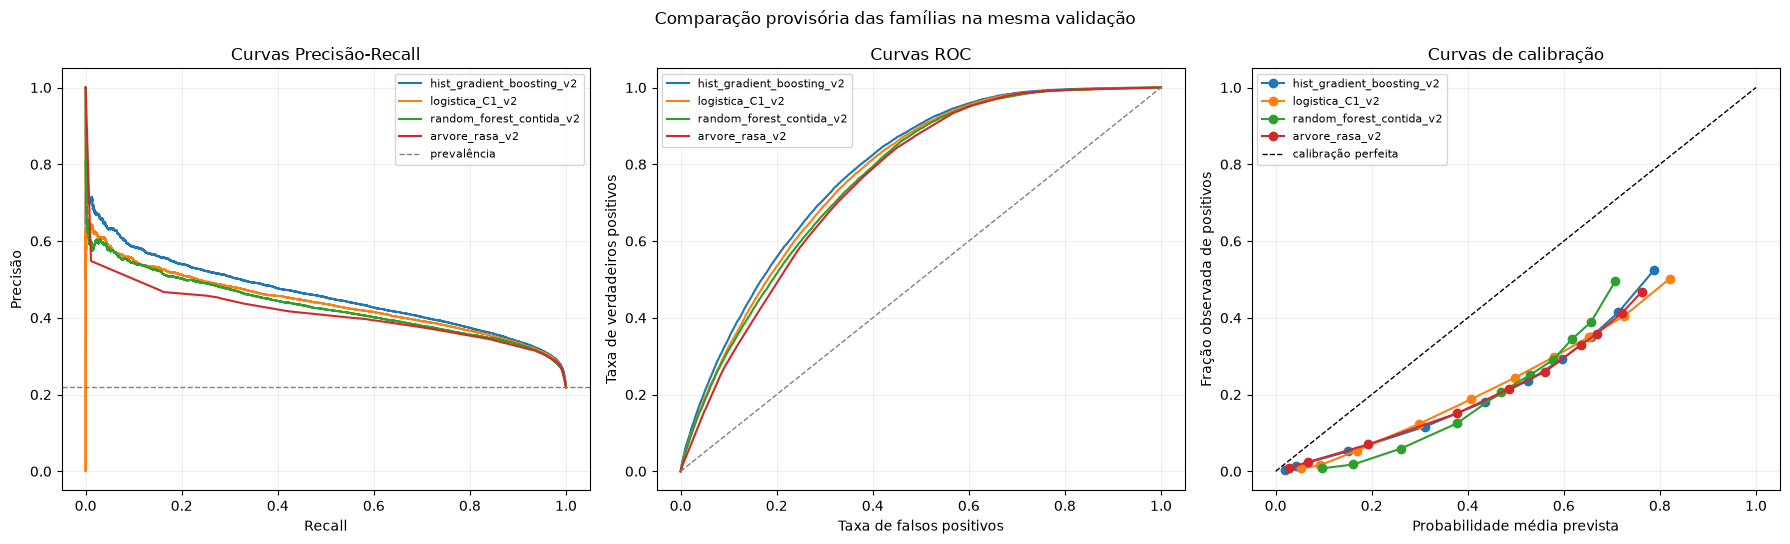

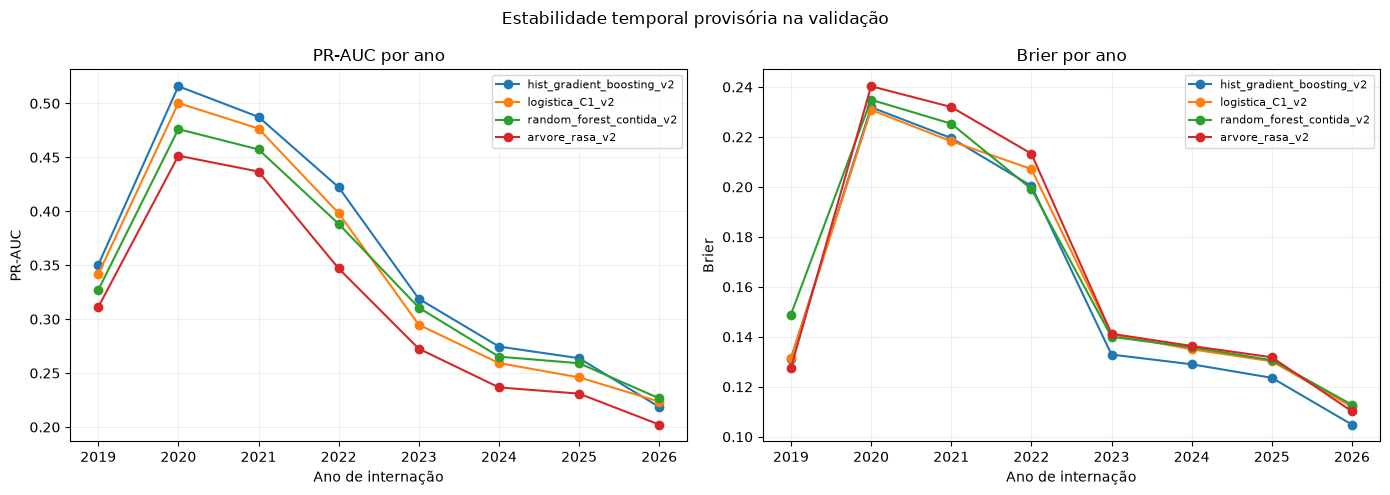

,modelo,ano_internacao,n,positivos,prevalencia,pr_auc,roc_auc,brier,probabilidade_media
0,arvore_rasa_v2,2019,1334,160,0.119940,0.311035,0.797961,0.127588,0.252465
1,arvore_rasa_v2,2020,30032,8402,0.279768,0.451507,0.722904,0.240289,0.519234
2,arvore_rasa_v2,2021,45369,12790,0.281911,0.436808,0.707329,0.231986,0.496559
3,arvore_rasa_v2,2022,14589,2649,0.181575,0.346957,0.763864,0.213303,0.427605
4,arvore_rasa_v2,2023,7377,706,0.095703,0.272592,0.825559,0.141221,0.276987
5,arvore_rasa_v2,2024,7034,586,0.083310,0.236733,0.812527,0.136350,0.264236
6,arvore_rasa_v2,2025,8886,651,0.073261,0.230944,0.828100,0.131817,0.259129
7,arvore_rasa_v2,2026,5379,298,0.055401,0.202277,0.845035,0.110205,0.219618
8,dummy_prior_v2,2019,1334,160,0.119940,0.119940,0.500000,0.115305,0.218683
9,dummy_prior_v2,2020,30032,8402,0.279768,0.279768,0.500000,0.205229,0.218683


,modelo,pr_auc_min,pr_auc_max,pr_auc_media,roc_auc_min,roc_auc_max,brier_min,brier_max,amplitude_pr_auc,amplitude_roc_auc
0,arvore_rasa_v2,0.202277,0.451507,0.311107,0.707329,0.845035,0.110205,0.240289,0.249231,0.137706
1,random_forest_contida_v2,0.226590,0.476159,0.338808,0.710650,0.851340,0.112817,0.234873,0.249569,0.140690
2,logistica_C1_v2,0.223552,0.500299,0.342568,0.725206,0.845175,0.112015,0.230842,0.276747,0.119969
3,hist_gradient_boosting_v2,0.218580,0.515883,0.356464,0.733906,0.855512,0.104886,0.231893,0.297303,0.121606


Figuras gravadas:
- C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\reports\figures\supervisionado_03\03_pilotos_curvas_pr_roc_calibracao.png
- C:\Users\olivem85\OneDrive - Pfizer\Documents\GitHub\Projeto_Integrador\reports\figures\supervisionado_03\03_pilotos_metricas_por_ano.png


In [34]:
# ============================================================
# 23. Diagnósticos de discriminação, calibração e estabilidade anual
# ============================================================

import matplotlib.pyplot as plt

from sklearn.calibration import calibration_curve
from sklearn.metrics import precision_recall_curve, roc_curve


FIGURES_DIR = ROOT_DIR / "reports" / "figures" / "supervisionado_03"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

modelos_avaliaveis = (
    resultados_cinco_familias.loc[
        resultados_cinco_familias["modelo"].ne("dummy_prior_v2"),
        "modelo",
    ]
    .tolist()
)

figura_curvas, eixos_curvas = plt.subplots(
    1,
    3,
    figsize=(18, 5.5),
)

prevalencia_validacao_piloto = float(
    y_validacao_piloto.mean()
)

for modelo in modelos_avaliaveis:
    dados_modelo = predicoes_cinco_familias_df.loc[
        predicoes_cinco_familias_df["modelo"].eq(modelo)
    ]

    precisao, recall, _ = precision_recall_curve(
        dados_modelo["y_true"],
        dados_modelo["y_prob"],
    )

    falso_positivo, verdadeiro_positivo, _ = roc_curve(
        dados_modelo["y_true"],
        dados_modelo["y_prob"],
    )

    fracao_positivos, media_prevista = calibration_curve(
        dados_modelo["y_true"],
        dados_modelo["y_prob"],
        n_bins=10,
        strategy="quantile",
    )

    eixos_curvas[0].plot(
        recall,
        precisao,
        label=modelo,
    )

    eixos_curvas[1].plot(
        falso_positivo,
        verdadeiro_positivo,
        label=modelo,
    )

    eixos_curvas[2].plot(
        media_prevista,
        fracao_positivos,
        marker="o",
        label=modelo,
    )


eixos_curvas[0].axhline(
    prevalencia_validacao_piloto,
    linestyle="--",
    color="gray",
    linewidth=1,
    label="prevalência",
)
eixos_curvas[0].set_title("Curvas Precisão-Recall")
eixos_curvas[0].set_xlabel("Recall")
eixos_curvas[0].set_ylabel("Precisão")

eixos_curvas[1].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    linewidth=1,
)
eixos_curvas[1].set_title("Curvas ROC")
eixos_curvas[1].set_xlabel("Taxa de falsos positivos")
eixos_curvas[1].set_ylabel("Taxa de verdadeiros positivos")

eixos_curvas[2].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black",
    linewidth=1,
    label="calibração perfeita",
)
eixos_curvas[2].set_title("Curvas de calibração")
eixos_curvas[2].set_xlabel("Probabilidade média prevista")
eixos_curvas[2].set_ylabel("Fração observada de positivos")

for eixo in eixos_curvas:
    eixo.grid(alpha=0.2)
    eixo.legend(fontsize=8)

figura_curvas.suptitle(
    "Comparação provisória das famílias na mesma validação"
)
figura_curvas.tight_layout()

caminho_figura_curvas = (
    FIGURES_DIR
    / "03_pilotos_curvas_pr_roc_calibracao.png"
)
figura_curvas.savefig(
    caminho_figura_curvas,
    dpi=160,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()
plt.close(figura_curvas)


metricas_por_ano = []

for (modelo, ano), grupo in (
    predicoes_cinco_familias_df.groupby(
        ["modelo", "ano_internacao"],
        sort=True,
        observed=True,
    )
):
    y_ano = grupo["y_true"].to_numpy(dtype=np.int8)
    prob_ano = grupo["y_prob"].to_numpy(dtype=float)

    if np.unique(y_ano).size < 2:
        roc_auc_ano = np.nan
        pr_auc_ano = np.nan
    else:
        roc_auc_ano = float(
            roc_auc_score(y_ano, prob_ano)
        )
        pr_auc_ano = float(
            average_precision_score(y_ano, prob_ano)
        )

    metricas_por_ano.append(
        {
            "modelo": modelo,
            "ano_internacao": int(ano),
            "n": int(len(grupo)),
            "positivos": int(y_ano.sum()),
            "prevalencia": float(y_ano.mean()),
            "pr_auc": pr_auc_ano,
            "roc_auc": roc_auc_ano,
            "brier": float(
                brier_score_loss(y_ano, prob_ano)
            ),
            "probabilidade_media": float(prob_ano.mean()),
        }
    )

metricas_por_ano_df = pd.DataFrame(
    metricas_por_ano
)

variacao_temporal_modelos = (
    metricas_por_ano_df.loc[
        metricas_por_ano_df["modelo"].ne("dummy_prior_v2")
    ]
    .groupby("modelo", observed=True)
    .agg(
        pr_auc_min=("pr_auc", "min"),
        pr_auc_max=("pr_auc", "max"),
        pr_auc_media=("pr_auc", "mean"),
        roc_auc_min=("roc_auc", "min"),
        roc_auc_max=("roc_auc", "max"),
        brier_min=("brier", "min"),
        brier_max=("brier", "max"),
    )
    .reset_index()
)

variacao_temporal_modelos["amplitude_pr_auc"] = (
    variacao_temporal_modelos["pr_auc_max"]
    - variacao_temporal_modelos["pr_auc_min"]
)

variacao_temporal_modelos["amplitude_roc_auc"] = (
    variacao_temporal_modelos["roc_auc_max"]
    - variacao_temporal_modelos["roc_auc_min"]
)

figura_temporal, eixos_temporais = plt.subplots(
    1,
    2,
    figsize=(14, 5),
)

for modelo in modelos_avaliaveis:
    dados_modelo = metricas_por_ano_df.loc[
        metricas_por_ano_df["modelo"].eq(modelo)
    ].sort_values("ano_internacao")

    eixos_temporais[0].plot(
        dados_modelo["ano_internacao"],
        dados_modelo["pr_auc"],
        marker="o",
        label=modelo,
    )

    eixos_temporais[1].plot(
        dados_modelo["ano_internacao"],
        dados_modelo["brier"],
        marker="o",
        label=modelo,
    )


eixos_temporais[0].set_title("PR-AUC por ano")
eixos_temporais[0].set_xlabel("Ano de internação")
eixos_temporais[0].set_ylabel("PR-AUC")

eixos_temporais[1].set_title("Brier por ano")
eixos_temporais[1].set_xlabel("Ano de internação")
eixos_temporais[1].set_ylabel("Brier")

for eixo in eixos_temporais:
    eixo.grid(alpha=0.2)
    eixo.legend(fontsize=8)

figura_temporal.suptitle(
    "Estabilidade temporal provisória na validação"
)
figura_temporal.tight_layout()

caminho_figura_temporal = (
    FIGURES_DIR
    / "03_pilotos_metricas_por_ano.png"
)
figura_temporal.savefig(
    caminho_figura_temporal,
    dpi=160,
    bbox_inches="tight",
    facecolor="white",
)
plt.show()
plt.close(figura_temporal)


display(
    metricas_por_ano_df.sort_values(
        ["modelo", "ano_internacao"]
    ).reset_index(drop=True)
)

display(
    variacao_temporal_modelos.sort_values(
        ["amplitude_pr_auc", "pr_auc_media"],
        ascending=[True, False],
    ).reset_index(drop=True)
)

print("Figuras gravadas:")
print("-", caminho_figura_curvas)
print("-", caminho_figura_temporal)


In [35]:
# ============================================================
# 24. Persistir a comparação provisória e registrar o próximo gate
# ============================================================

import json


timestamp_comparacao = pd.Timestamp.now(
    tz="UTC"
).strftime("%Y%m%dT%H%M%SZ")

prefixo_comparacao = (
    f"03_cinco_familias_{STATUS_COORTE}_"
    f"{timestamp_comparacao}"
)

caminho_resultados_cinco = (
    Path(TABLES_DIR)
    / f"{prefixo_comparacao}_metricas.csv"
)

caminho_metricas_ano = (
    Path(TABLES_DIR)
    / f"{prefixo_comparacao}_metricas_por_ano.csv"
)

caminho_variacao_temporal = (
    Path(TABLES_DIR)
    / f"{prefixo_comparacao}_variacao_temporal.csv"
)

caminho_amostras = (
    Path(TABLES_DIR)
    / f"{prefixo_comparacao}_amostras.csv"
)

caminho_predicoes_cinco = (
    Path(PREDICTIONS_DIR)
    / f"{prefixo_comparacao}_predicoes_validacao.parquet"
)

caminho_manifesto_cinco = (
    Path(TABLES_DIR)
    / f"{prefixo_comparacao}_manifesto.json"
)

resultados_cinco_familias.to_csv(
    caminho_resultados_cinco,
    index=False,
    encoding="utf-8-sig",
)

metricas_por_ano_df.to_csv(
    caminho_metricas_ano,
    index=False,
    encoding="utf-8-sig",
)

variacao_temporal_modelos.to_csv(
    caminho_variacao_temporal,
    index=False,
    encoding="utf-8-sig",
)

resumo_amostras_comparacao.to_csv(
    caminho_amostras,
    index=False,
    encoding="utf-8-sig",
)

predicoes_cinco_familias_df.to_parquet(
    caminho_predicoes_cinco,
    index=False,
)


ranking_provisorio = (
    resultados_cinco_familias.loc[
        resultados_cinco_familias["modelo"].ne("dummy_prior_v2")
    ]
    .copy()
    .sort_values(
        ["pr_auc", "brier", "duracao_fit_s"],
        ascending=[False, True, True],
    )
    .reset_index(drop=True)
)

shortlist_provisoria = ranking_provisorio.head(2)[
    "modelo"
].tolist()

manifesto_cinco = {
    "status_coorte": STATUS_COORTE,
    "versao_execucao": VERSAO_COMPARACAO,
    "carater": "comparacao_provisoria_de_integracao",
    "seed": int(SEED),
    "n_treino_piloto": int(len(X_treino_piloto)),
    "n_validacao_piloto": int(len(X_validacao_piloto)),
    "features": list(FEATURES_PILOTO),
    "modelos": list(modelos_piloto.keys()),
    "shortlist_provisoria": shortlist_provisoria,
    "teste_aberto": False,
    "limiar_selecionado": False,
    "calibracao_aplicada": False,
    "tuning_realizado": False,
    "observacoes": [
        "Resultados dependem da coorte provisória.",
        "Amostras comparáveis foram usadas para controlar custo.",
        "A shortlist não congela finalistas.",
        "O teste permaneceu fechado.",
        "Calibração e limiar pertencem à próxima etapa.",
    ],
    "artefatos": {
        "metricas": str(caminho_resultados_cinco),
        "metricas_por_ano": str(caminho_metricas_ano),
        "variacao_temporal": str(caminho_variacao_temporal),
        "amostras": str(caminho_amostras),
        "predicoes_validacao": str(caminho_predicoes_cinco),
        "figura_curvas": str(caminho_figura_curvas),
        "figura_temporal": str(caminho_figura_temporal),
    },
}

caminho_manifesto_cinco.write_text(
    json.dumps(
        manifesto_cinco,
        indent=2,
        ensure_ascii=False,
        default=str,
    ),
    encoding="utf-8",
)


# Round-trip dos principais artefatos.
resultados_reabertos = pd.read_csv(
    caminho_resultados_cinco,
    encoding="utf-8-sig",
)

predicoes_reabertas = pd.read_parquet(
    caminho_predicoes_cinco
)

manifesto_reaberto_cinco = json.loads(
    caminho_manifesto_cinco.read_text(
        encoding="utf-8"
    )
)

validacoes_comparacao = {
    "cinco_modelos_registrados": len(resultados_reabertos) == 5,
    "cinco_modelos_com_predicoes": predicoes_reabertas["modelo"].nunique() == 5,
    "probabilidades_validas": predicoes_reabertas["y_prob"].between(0, 1).all(),
    "teste_permaneceu_fechado": manifesto_reaberto_cinco["teste_aberto"] is False,
    "status_provisorio": manifesto_reaberto_cinco["status_coorte"] == "provisoria",
    "sem_tuning": manifesto_reaberto_cinco["tuning_realizado"] is False,
    "sem_limiar_final": manifesto_reaberto_cinco["limiar_selecionado"] is False,
    "figuras_existentes": caminho_figura_curvas.exists() and caminho_figura_temporal.exists(),
}

validacoes_comparacao_df = pd.DataFrame(
    {
        "verificacao": validacoes_comparacao.keys(),
        "resultado": validacoes_comparacao.values(),
    }
)

display(validacoes_comparacao_df)

if not all(validacoes_comparacao.values()):
    falhas = [
        chave
        for chave, valor in validacoes_comparacao.items()
        if not valor
    ]
    raise RuntimeError(
        "Falhas na comparação provisória: "
        f"{falhas}"
    )

print("Shortlist provisória, sem congelamento:", shortlist_provisoria)
print("Artefatos da comparação gravados com sucesso.")
print("O teste permaneceu fechado.")
print("Próximo gate: coorte definitiva, features congeladas, tuning limitado, calibração e limiar.")


,verificacao,resultado
0,cinco_modelos_registrados,True
1,cinco_modelos_com_predicoes,True
2,probabilidades_validas,True
3,teste_permaneceu_fechado,True
4,status_provisorio,True
5,sem_tuning,True
6,sem_limiar_final,True
7,figuras_existentes,True


Shortlist provisória, sem congelamento: ['hist_gradient_boosting_v2', 'logistica_C1_v2']
Artefatos da comparação gravados com sucesso.
O teste permaneceu fechado.
Próximo gate: coorte definitiva, features congeladas, tuning limitado, calibração e limiar.


## Conclusão provisória ampliada

Esta execução confirmou que o fluxo supervisionado provisório funciona
ponta a ponta e permitiu comparar, sob a mesma amostra de treino e
validação:

- baseline Dummy;
- regressão logística;
- árvore de decisão rasa;
- Random Forest com configuração contida;
- HistGradientBoosting com configuração contida.

A comparação utiliza a mesma lista provisória de features, as mesmas
partições e a mesma amostra estratificada por ano e alvo. Imputação,
codificação e escala foram ajustadas somente no treino de cada pipeline.

Os resultados continuam provisórios. A tabela comparativa serve para
verificar viabilidade, custo, discriminação, calibração e estabilidade
temporal das famílias, mas não congela modelo final, hiperparâmetros,
limiar ou método de calibração.

### Reprodutibilidade após a centralização

A comparação das cinco famílias foi repetida depois da substituição dos
pré-processadores, métricas e construtores locais pelos componentes
centrais do projeto.

O ranking dos modelos permaneceu inalterado:

1. HistGradientBoosting;
2. regressão logística;
3. Random Forest;
4. árvore de decisão rasa;
5. baseline Dummy.

As diferenças observadas entre a execução anterior e a execução
centralizada foram pequenas e não alteraram nenhuma conclusão
comparativa. A maior diferença absoluta de PR-AUC foi inferior a 0,0002,
observada no HistGradientBoosting. O Dummy e a árvore rasa reproduziram
os mesmos valores de PR-AUC, ROC-AUC e Brier apresentados anteriormente.

| Família | PR-AUC anterior | PR-AUC centralizada | Diferença |
|---|---:|---:|---:|
| HistGradientBoosting | 0,459686 | 0,459492 | -0,000194 |
| Regressão logística | 0,439183 | 0,439229 | +0,000046 |
| Random Forest | 0,429916 | 0,430058 | +0,000142 |
| Árvore de decisão rasa | 0,399220 | 0,399220 | 0,000000 |
| Dummy | 0,218683 | 0,218683 | 0,000000 |

Essas diferenças são pequenas demais para representar mudança material
no desempenho comparativo. A centralização preservou o comportamento dos
modelos, o ranking das famílias e a shortlist operacional, ao mesmo tempo
que reduziu a duplicação de regras entre o notebook e os módulos de
produção.

A reprodução não transforma os resultados em avaliação final. Ela
demonstra que a refatoração não introduziu regressão relevante no
experimento piloto e que o fluxo centralizado produz resultados
compatíveis com a implementação anterior.

### Discriminação, calibração e estabilidade temporal

As curvas de Precisão-Recall e ROC avaliam discriminação na validação. A
curva de calibração compara probabilidades previstas com a frequência
observada, sem que qualquer correção de calibração tenha sido aplicada
nesta etapa.

A avaliação por ano deve ser interpretada como diagnóstico de robustez
interna. Variações de PR-AUC, ROC-AUC ou Brier entre 2019 e 2026 podem
refletir mudanças epidemiológicas, demográficas, de cobertura e de
documentação já identificadas nas análises exploratórias. O ano de 2026
permanece parcial.

A shortlist gerada é apenas operacional. Ela identifica até duas
famílias para continuidade técnica, mas deverá ser recalculada depois da
chegada da coorte definitiva e do congelamento da seleção final de
colunas.

As curvas de calibração permaneceram predominantemente abaixo da
diagonal de referência, indicando superestimação das probabilidades
observadas em parte relevante da distribuição. Esse comportamento é
compatível com o caráter ainda não calibrado dos pilotos e pode ser
influenciado pelo uso de pesos balanceados. Por isso, as probabilidades
brutas não devem ser interpretadas como riscos absolutos nesta etapa.
Brier, PR-AUC e ROC-AUC serão avaliados conjuntamente após o ajuste
limitado dos finalistas.

A redução da PR-AUC nos anos mais recentes não deve ser interpretada
isoladamente como deterioração do modelo, pois a métrica depende da
prevalência e da composição de cada período. A estabilidade temporal
será reavaliada com a coorte definitiva, mantendo 2026 identificado como
período parcial.

### Isolamento do conjunto de teste

O conjunto de teste permaneceu fechado durante toda a comparação. O
notebook criou e persistiu a atribuição da partição, mas não materializou
um DataFrame, matriz de features, vetor de alvo, probabilidade, métrica ou
gráfico específico do teste.

Todas as comparações entre famílias, o ranking operacional e a shortlist
foram calculados exclusivamente com treino e validação. Não houve tuning,
escolha de limiar, calibração, análise final por subgrupo nem
interpretação definitiva de importância de variáveis.

### Próximo gate

A próxima etapa somente deverá começar após:

- recebimento e validação da coorte definitiva;
- correção dos metadados técnicos da coorte de origem;
- congelamento da lista final de features;
- reprodução ou importação da partição oficial;
- confirmação da ausência de vazamento;
- repetição dos pilotos comparáveis;
- recalculação da shortlist na coorte definitiva;
- escolha de no máximo dois finalistas;
- tuning limitado no treino;
- confirmação dos candidatos na validação;
- calibração e escolha de limiar sem acesso ao teste.

A abertura do teste ocorrerá uma única vez, depois do congelamento do
modelo, das features, dos hiperparâmetros, do método de calibração e do
limiar operacional.